In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.stats import qmc, multivariate_normal
import matplotlib.pyplot as plt
from data_l63_v1 import create_and_save_dataset, load_dataset_loaders
import torch
from ml_models import ConditionalNF, train_conditional_nf, ConditionalNF_LSTM_v2
from util_ml import *
from inference_util import evaluate_conditional_nf
import json
import sys
from util_plots import *
from util_metrics import *

# Load the dataset-
Only run this if you need new dataset, otherwise jump to the next block

# Define the model and training parameters

## The block below sets-up all the experimenst that we have

In [3]:
# ============================================================
# STUDY 1: Effect of Temporal Extent (Fixed dt_subsample=1)
# ============================================================
study1_temporal_extent = [
    # (T_window, dt_subsample, T_obs in time units, L_actual points)
    (1, 1, 0.01, 1),      # Snapshot
    (5, 1, 0.05, 5),      # Very short
    (10, 1, 0.10, 10),    # Sub-orbital
    (50, 1, 0.50, 50),    # ~Half orbit
    (100, 1, 1.00, 100),  # ~1 orbit
    (200, 1, 2.00, 200),  # ~2 orbits
]

# ============================================================
# STUDY 2a: Effect of Sampling (Short extent, T_obs=2)
# ============================================================
# study2a_sampling_short = [
#     # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
#     # (200, 1, 2.00, 200, 0.01),  # Fully resolved baseline
#     (200, 2, 2.00, 100, 0.02),  # 2x subsampling
#     (200, 5, 2.00, 40, 0.05),   # 5x subsampling
#     (200, 10, 2.00, 20, 0.10),  # 10x subsampling
#     (200, 20, 2.00, 10, 0.20),  # 20x subsampling
#     (200, 50, 2.00, 4, 0.50),   # 50x subsampling (very coarse)
# ]
study2a_sampling_short = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    (200, 1, 2.00, 200, 0.01),  # Fully resolved baseline
    # (200, 2, 2.00, 100, 0.02),  # 2x subsampling
    # (200, 4, 2.00, 10, 0.20),  # 20x subsampling

    # (200, 5, 2.00, 40, 0.05),   # 5x subsampling
    # (200, 10, 2.00, 20, 0.10),  # 10x subsampling
    # (200, 20, 2.00, 10, 0.20),  # 20x subsampling
    # (200, 30, 2.00, 10, 0.20),  # 20x subsampling

    # (200, 50, 2.00, 4, 0.50),   # 50x subsampling (very coarse)
    (200, 100, 2.00, 4, 0.50),   # 50x subsampling (very coarse)

]

# ============================================================
# STUDY 2b: Effect of Sampling (Long extent, T_obs=10)
# ============================================================
study2b_sampling_long = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    # (1000, 1, 10.00, 1000, 0.01),  # Fully resolved baseline
    (1000, 5, 10.00, 200, 0.05),   # 5x subsampling
    (1000, 10, 10.00, 100, 0.10),  # 10x subsampling
    (1000, 20, 10.00, 50, 0.20),   # 20x subsampling
    (1000, 50, 10.00, 20, 0.50),   # 50x subsampling
]
study3a_sampling_short_avg = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    # # (200, 1, 2.00, 200, 0.01),  # Fully resolved baseline
    # (200, 2, 2.00, 100, 0.02),  # 2x subsampling
    # (200, 5, 2.00, 40, 0.05),   # 5x subsampling
    # (200, 10, 2.00, 20, 0.10),  # 10x subsampling
    # (200, 20, 2.00, 10, 0.20),  # 20x subsampling
    # (200, 50, 2.00, 4, 0.50),   # 50x subsampling (very coarse)
    (200, 100, 2.00, 4, 0.50),   # 100x subsampling (very coarse)

]

# ============================================================
# STUDY 3: Summary Statistics Baselines
# ============================================================
# Use selected T_window values with avg=True
study3_summaries = [
    # Compare at key temporal extents
    (50, 1),    # T_obs = 0.5
    (100, 1),   # T_obs = 1.0
    (500, 1),   # T_obs = 5.0
    (1000, 1),  # T_obs = 10.0
]

# ============================================================
# COMBINED EXPERIMENTAL GRID
# ============================================================
all_experiments = {
    'study1_temporal_extent': study1_temporal_extent,
    # 'study2a_sampling_short': study2a_sampling_short,
    # 'study2b_sampling_long': study2b_sampling_long,
    # 'study3a_sampling_short_avg': study3a_sampling_short_avg,
    # 'study3_summaries': study3_summaries,
}

In [43]:
# ============================================================
# STUDY 1: Effect of Temporal Extent (Fixed dt_subsample=1)
# ============================================================
study1_temporal_extent = [
    # (T_window, dt_subsample, T_obs in time units, L_actual points)
    (1, 1, 0.01, 1),      # Snapshot
    (2, 1, 0.01, 1),      # Snapshot
    
    # (5, 1, 0.05, 5),      # Very short
    # (10, 1, 0.10, 10),    # Sub-orbital
    # (50, 1, 0.50, 50),    # ~Half orbit
    # (100, 1, 1.00, 100),  # ~1 orbit
    # (200, 1, 2.00, 200),  # ~2 orbits
]

# ============================================================
# STUDY 2a: Effect of Sampling (Short extent, T_obs=2)
# ============================================================
study2a_sampling_short = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    # (200, 1, 2.00, 200, 0.01),  # Fully resolved baseline
    # (200, 2, 2.00, 100, 0.02),  # 2x subsampling
    # (200, 5, 2.00, 40, 0.05),   # 5x subsampling
    # (200, 10, 2.00, 20, 0.10),  # 10x subsampling
    # (200, 20, 2.00, 10, 0.20),  # 20x subsampling
    (200, 100, 2.00, 4, 0.50),   # 50x subsampling (very coarse)
]

# ============================================================
# STUDY 2b: Effect of Sampling (Long extent, T_obs=10)
# ============================================================
study2b_sampling_long = [
    # (T_window, dt_subsample, T_obs, L_actual, Δt_actual)
    # (1000, 1, 10.00, 1000, 0.01),  # Fully resolved baseline
    (1000, 5, 10.00, 200, 0.05),   # 5x subsampling
    # (1000, 10, 10.00, 100, 0.10),  # 10x subsampling
    # (1000, 20, 10.00, 50, 0.20),   # 20x subsampling
    # (1000, 50, 10.00, 20, 0.50),   # 50x subsampling
]

# ============================================================
# STUDY 3: Summary Statistics Baselines
# ============================================================
# Use selected T_window values with avg=True
study3_summaries = [
    # Compare at key temporal extents
    (50, 1),    # T_obs = 0.5
    (100, 1),   # T_obs = 1.0
    (500, 1),   # T_obs = 5.0
    (1000, 1),  # T_obs = 10.0
]

# ============================================================
# COMBINED EXPERIMENTAL GRID
# ============================================================
all_experiments = {
    'study1_temporal_extent': study1_temporal_extent,
    # 'study2a_sampling_short': study2a_sampling_short,
    # 'study2b_sampling_long': study2b_sampling_long,
    # 'study3_summaries': study3_summaries,
}

## Ineference for all experiments

In [31]:
all_experiments

{'study2a_sampling_short': [(200, 100, 2.0, 4, 0.5)]}

In [5]:
models_dict_v2 = {}
def normalize_parameters_l63(x_true, x_samples):
    """
    Normalize the L63 parameters to the range [0, 1] based on known min and max values.
    
    Args:
        x_true: shape (ncc, nfeatures)
        x_samples: shape (ncc, nsample, nfeatures)
    """
    # Compute per-feature min and max from the true data
    x_min = x_true.min(axis=0)          # shape: (nfeatures,)
    x_max = x_true.max(axis=0)          # shape: (nfeatures,)
    scale = x_max - x_min               # shape: (nfeatures,)
    print(x_min.shape)

    # Avoid divide-by-zero for constant features
    scale[scale == 0] = 1.0

    # Normalize x_true to [0, 1]
    x_true_norm = (x_true - x_min) / scale  # shape: (ncc, nfeatures)

    # Normalize x_samples using the SAME scaling
    # x_samples: (ncc, nsample, nfeatures)
    # We need to broadcast x_min and scale across the nsample dimension (axis=1)
    x_min_expanded = x_min[np.newaxis, np.newaxis, :]    # (1, 1, nfeatures)
    scale_expanded = scale[np.newaxis, np.newaxis, :]    # (1, 1, nfeatures)

    x_samples_norm = (x_samples - x_min_expanded) / scale_expanded
    return x_true_norm, x_samples_norm

# Run all studies
for study_name, experiment_list in all_experiments.items():
    print(f"\n{'='*80}")
    print(f"RUNNING {study_name.upper()}")
    print(f"{'='*80}\n")
    
    study_results = []
    
    for experiment in experiment_list:
        T_window = experiment[0]
        dt_subsample = experiment[1]
        
        # Determine if this is a summary statistics experiment
        use_avg = (study_name == 'study3_summaries')
        use_subsample_avg = (study_name == 'study3a_sampling_short_avg')

        
        for case in ['easy']:#, 'intermediate', 'hard']:
            print(f"\n{'-'*60}")
            print(f"Configuration: T_window={T_window}, dt_subsample={dt_subsample}, case={case}")
            if use_avg:
                print(f"Mode: SUMMARY STATISTICS (temporal mean)")
            else:
                print(f"Mode: FULL TRAJECTORY")
            print(f"Effective: T_obs={T_window*0.01:.2f} time units, "
                  f"Δt={dt_subsample*0.01:.3f}, L={T_window//dt_subsample} points")
            print(f"{'-'*60}\n")
            
            # Load dataset
            train_loader, test_loader = load_dataset_loaders(
                f"./data/l63_LATENT_GMM_dt1_T1000_w28_{case}.npz", 
                batch_size=128,
                T_window=T_window,
                dt=dt_subsample,
                direct_params=True,
                avg=use_avg,
                use_subsample_avg=use_subsample_avg   
            )
            
            # Train model
            model_name = f"{study_name}_T{T_window}_dt{dt_subsample}_{case}"
            if use_avg:
                model_name += "_avg"
            if use_subsample_avg:
                model_name += "_subsample_avg"
            print(f"Training model: {model_name}")
            
            # Load configuration
            json_path = ""
            json_full_path = os.path.join(json_path, "L63_config_v0.json")
            with open(json_full_path, 'r') as f:
                config = json.load(f)
            
            network_params = config["network_params"]
            train_params = config["training_params"]
            
            # Update parameters
            train_params["patience"] = 10
            train_params["learning_rate"] = 0.0005
            train_params["max_epochs"] = 300
            train_params["batch_size"] = 128
            network_params['hidden_dims'] = [64, 128, 128]## old one for ANN
            network_params['hidden_dims'] = [64, 64]

            n_time = int(T_window / dt_subsample + 0.1)
            network_params["n_time"] = n_time
            if use_avg:
                network_params["n_time"] = 1  # No change
            
            # Define paths and names
            run_name = f"lstm_l63_GMM_dt{dt_subsample}_T{T_window}_w28_{case}"
            if use_avg:
                run_name = f"lstm_l63_GMM_dt{dt_subsample}_T{T_window}_w28_avg_{case}"
            if use_subsample_avg:
                run_name = f"lstm_l63_GMM_dt{dt_subsample}_T{T_window}_w28_subsample_avg_{case}"
                
            checkpoint_path = f"./save_models_new/nflow_{run_name}_v2.pt"
            
            print(f"Run name: {run_name}")
            print(f"Network params: {network_params}")
            
            # Configure device
            device_id = train_params["device_id"]
            device = configure_device(device_id)
            
            # Initialize model
            model = ConditionalNF_LSTM_v2(**network_params).to(device)
            optimizer = torch.optim.Adam(
                filter(lambda p: p.requires_grad, model.parameters()),
                lr=train_params["learning_rate"],
                weight_decay=train_params["weight_decay"]
            )
            
        
            # Load from checkpoint
            model = load_from_checkpoint(model, optimizer, checkpoint_path, device)
            model.eval()  # Set to evaluation mode

            _ , c_vals, x_true, x_samples = evaluate_conditional_nf(model, test_loader, device=device, n_samples=300)
            #normalize to 0,1 
            x_true, x_samples = normalize_parameters_l63(x_true, x_samples)
            
            # Store model and dataloaders with key

            key = model_name
            models_dict_v2[key] = {
                'model': model,
                'test_loader': test_loader,
                'network_params': network_params,
                'run_name': run_name,
                'T_window': T_window,
                'dt_subsample': dt_subsample,
                'conditionals':c_vals,
                'params_true': x_true,
                'params_generated':x_samples,



            }
            
            print(f"Successfully loaded model: {key}\n")
keys =  list(models_dict_v2.keys())


RUNNING STUDY1_TEMPORAL_EXTENT


------------------------------------------------------------
Configuration: T_window=1, dt_subsample=1, case=easy
Mode: FULL TRAJECTORY
Effective: T_obs=0.01 time units, Δt=0.010, L=1 points
------------------------------------------------------------

torch.Size([10240, 3]) torch.Size([10240, 1, 3])
Training model: study1_temporal_extent_T1_dt1_easy
Run name: lstm_l63_GMM_dt1_T1_w28_easy
Network params: {'hidden_dims': [64, 64], 'x_dim': 3, 'cond_dim': 3, 'n_time': 1, 'n_flow_layers': 4}
CUDA not available. Using CPU.
 Loaded checkpoint './save_models_new/nflow_lstm_l63_GMM_dt1_T1_w28_easy_v2.pt'
Average NLL on evaluation set: 1.0278
(3,)
Successfully loaded model: study1_temporal_extent_T1_dt1_easy


------------------------------------------------------------
Configuration: T_window=5, dt_subsample=1, case=easy
Mode: FULL TRAJECTORY
Effective: T_obs=0.05 time units, Δt=0.010, L=5 points
------------------------------------------------------------

t

## Run scatter plots and histograms for all experiments

In [6]:
keys

['study1_temporal_extent_T1_dt1_easy',
 'study1_temporal_extent_T5_dt1_easy',
 'study1_temporal_extent_T10_dt1_easy',
 'study1_temporal_extent_T50_dt1_easy',
 'study1_temporal_extent_T100_dt1_easy',
 'study1_temporal_extent_T200_dt1_easy']

## Looking at the coverage for all experiments. This plot yet does not make much sense to me! 

In [34]:
keys =  list(models_dict_v2.keys())


# Usage
for key in [keys[0],keys[1],keys[5],keys[10],keys[15],keys[-1]]:
    print (f"Computing coverage for model: {key}")
    param_labels = ['rho', 'sigma', 'beta']

    empirical_coverage, credible_levels = compute_coverage_analysis(
        models_dict, key, credible_levels=[0.5, 0.68, 0.90, 0.95]
    )

    fig = plot_calibration(empirical_coverage, credible_levels, param_labels)
    # plt.savefig(f'./plots/calibration_plot_{key}.png', dpi=300, bbox_inches='tight')
plt.show()

# # Print numerical results
# print("Empirical Coverage Results:")
# for level in credible_levels:
#     print(f"\n{level*100:.0f}% Credible Interval:")
#     for i, label in enumerate(param_labels):
#         print(f"  {label}: {empirical_coverage[level][i]:.3f}")

IndexError: list index out of range

## Parameter Recovery for some of the experimensts- R2 seems too large for some cases when we compare to what we see visually!

From this plot we can identify cases where the nflow is doing bad and then investigate why it is doing bad on those cases

Computing parameter recovery for model: study1_temporal_extent_T1_dt1_easy


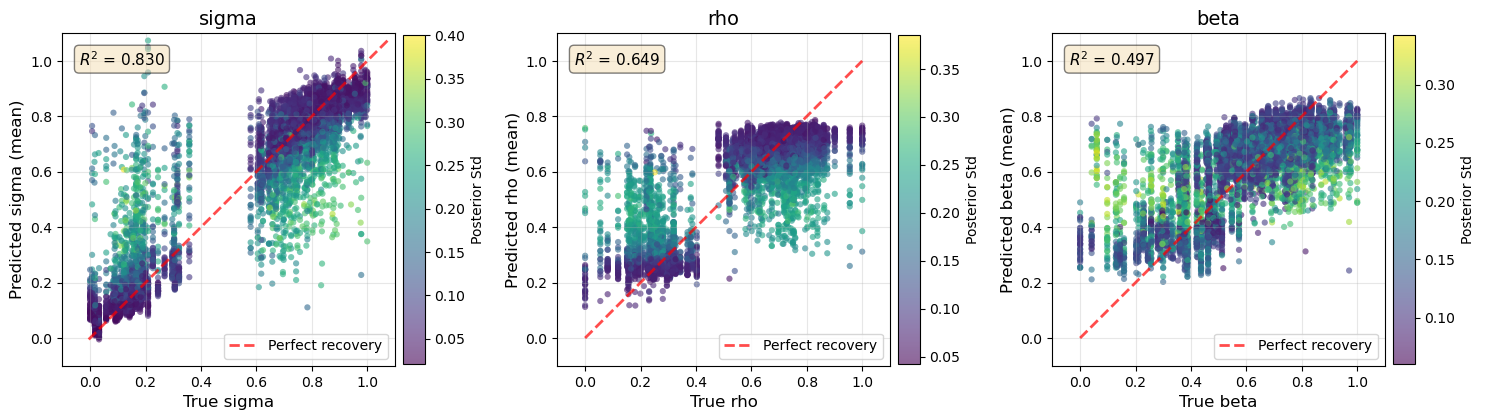

Computing parameter recovery for model: study1_temporal_extent_T2_dt1_easy


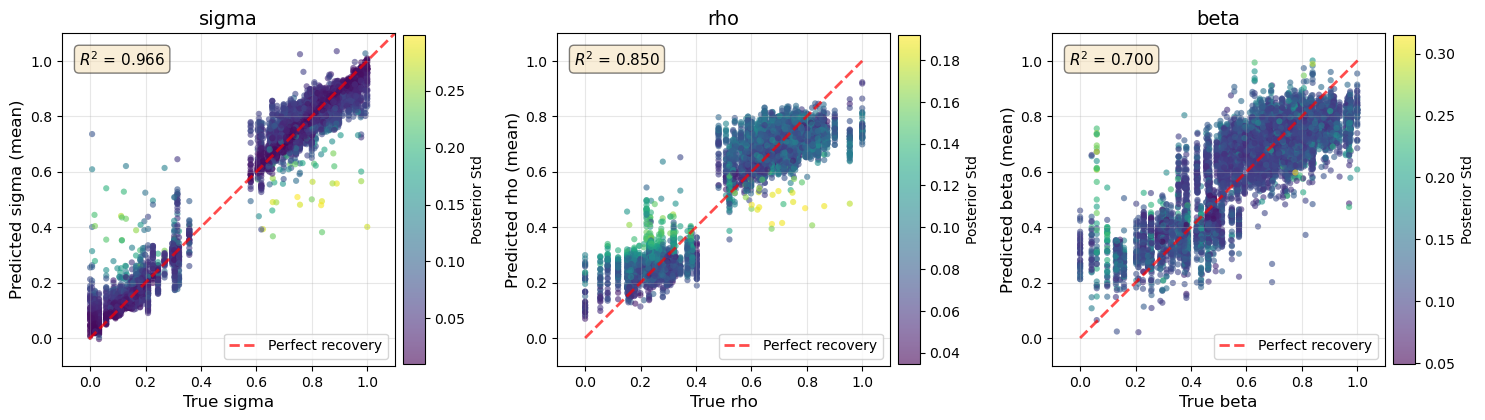

In [46]:


# Usage
for key in [keys[-2],keys[-1]]:
    print (f"Computing parameter recovery for model: {key}")
    param_labels = ['sigma','rho',  'beta']

    fig = plot_parameter_recovery(models_dict_v2, key, param_labels)
    # plt.savefig(f'parameter_recovery_{key}.png', dpi=300, bbox_inches='tight')
    plt.show()



In [ ]:
keys = list(models_dict_v2.keys())
keys.pop(6)
keys.pop(6)

keys

['study1_temporal_extent_T1_dt1_easy',
 'study1_temporal_extent_T5_dt1_easy',
 'study1_temporal_extent_T10_dt1_easy',
 'study1_temporal_extent_T50_dt1_easy',
 'study1_temporal_extent_T100_dt1_easy',
 'study1_temporal_extent_T200_dt1_easy',
 'study2b_sampling_long_T1000_dt5_easy',
 'study2b_sampling_long_T1000_dt10_easy',
 'study2b_sampling_long_T1000_dt20_easy',
 'study2b_sampling_long_T1000_dt50_easy',
 'study3a_sampling_short_avg_T200_dt2_easy_subsample_avg',
 'study3a_sampling_short_avg_T200_dt5_easy_subsample_avg',
 'study3a_sampling_short_avg_T200_dt10_easy_subsample_avg',
 'study3a_sampling_short_avg_T200_dt20_easy_subsample_avg',
 'study3a_sampling_short_avg_T200_dt50_easy_subsample_avg',
 'study3_summaries_T50_dt1_easy_avg',
 'study3_summaries_T100_dt1_easy_avg',
 'study3_summaries_T500_dt1_easy_avg',
 'study3_summaries_T1000_dt1_easy_avg']

## Here we create the metrics for all experiments

In [7]:
def identify_modes_and_compute_metrics(theta_true, theta_pred, n_modes=2, param_idx=None, param_name=None):
    """
    Identify modes in the true parameter distribution and compute R² per mode
    
    Args:
        theta_true: (N, 3) true parameters
        theta_pred: (N, 3) predicted parameters
        n_modes: number of modes to identify (default 2 for bimodal)
        param_idx: which parameter to analyze (0=sigma, 1=rho, 2=beta)
        param_name: name of parameter for printing
    
    Returns:
        Dictionary with per-mode metrics
    """
    from sklearn.mixture import GaussianMixture
    from sklearn.metrics import mean_squared_error, r2_score
    
    if param_idx is None:
        print("Error: Must specify param_idx")
        return None
    
    # Extract parameter values
    true_vals = theta_true[:, param_idx].reshape(-1, 1)
    pred_vals = theta_pred[:, param_idx]
    
    # Fit GMM to identify modes in TRUE parameters
    gmm = GaussianMixture(n_components=n_modes, random_state=42)
    mode_labels = gmm.fit_predict(true_vals)
    
    print(f"\n{'='*60}")
    print(f"Analysis for {param_name}: Identified {n_modes} modes")
    print(f"{'='*60}")
    
    mode_metrics = {}
    
    for mode in range(n_modes):
        mask = mode_labels == mode
        n_samples = mask.sum()
        
        if n_samples < 10:
            print(f"  Mode {mode}: Too few samples ({n_samples}), skipping")
            continue
        
        # Get data for this mode
        true_mode = theta_true[mask, param_idx]
        pred_mode = theta_pred[mask, param_idx]
        
        # Compute metrics
        r2 = r2_score(true_mode, pred_mode)
        rmse = np.sqrt(mean_squared_error(true_mode, pred_mode))
        mae = np.abs(true_mode - pred_mode).mean()
        bias = (pred_mode - true_mode).mean()
        
        # Residual analysis
        residuals = pred_mode - true_mode
        from scipy.stats import linregress
        slope, intercept, r_val, p_val, std_err = linregress(true_mode, residuals)
        
        # Store metrics
        mode_metrics[f'mode_{mode}'] = {
            'n_samples': int(n_samples),
            'true_mean': float(true_mode.mean()),
            'true_std': float(true_mode.std()),
            'true_range': (float(true_mode.min()), float(true_mode.max())),
            'r2': float(r2),
            'rmse': float(rmse),
            'mae': float(mae),
            'bias': float(bias),
            'residual_slope': float(slope),
            'residual_pvalue': float(p_val)
        }
        
        # Print results
        print(f"\n  Mode {mode}:")
        print(f"    Samples: {n_samples}")
        print(f"    True value range: [{true_mode.min():.3f}, {true_mode.max():.3f}]")
        print(f"    True mean ± std: {true_mode.mean():.3f} ± {true_mode.std():.3f}")
        print(f"    R²: {r2:.4f}")
        print(f"    RMSE: {rmse:.4f}")
        print(f"    MAE: {mae:.4f}")
        print(f"    Bias: {bias:+.4f}")
        print(f"    Residual slope: {slope:.4f} (p={p_val:.4e})")
        
        if p_val < 0.05:
            print(f"    ⚠️  Systematic bias detected!")
        else:
            print(f"    ✓ No systematic bias")
    
    return mode_metrics, mode_labels


def compute_metrics_with_mode_analysis(theta_true, theta_pred, n_modes=2):
    """
    Enhanced version that includes per-mode analysis for all parameters
    All metrics are truncated to 2 decimal places (not rounded)
    """
    from sklearn.metrics import mean_squared_error, mean_absolute_error
    import math
    
    def truncate_to_2_decimals(value):
        """Truncate to 2 decimal places without rounding"""
        return math.floor(value * 100) / 100
    
    metrics = {}
    params = [ 'sigma','rho', 'beta']
    
    print("\n" + "="*80)
    print("OVERALL METRICS")
    print("="*80)
    
    for i, param in enumerate(params):
        residuals = theta_pred[:, i] - theta_true[:, i]
        
        # Basic accuracy - truncate to 2 decimals
        metrics[f'{param}_rmse'] = truncate_to_2_decimals(
            np.sqrt(mean_squared_error(theta_true[:, i], theta_pred[:, i]))
        )
        metrics[f'{param}_mae'] = truncate_to_2_decimals(
            mean_absolute_error(theta_true[:, i], theta_pred[:, i])
        )
        
        # Bias - truncate to 2 decimals
        metrics[f'{param}_bias'] = truncate_to_2_decimals(residuals.mean())
        
        # Correlation (what R² measures) - truncate to 2 decimals
        metrics[f'{param}_r2'] = truncate_to_2_decimals(
            np.corrcoef(theta_true[:, i], theta_pred[:, i])[0,1]**2
        )
        
        # Systematic error detection
        from scipy.stats import linregress
        slope, intercept, r_value, p_value, std_err = linregress(theta_true[:, i], residuals)
        
        metrics[f'{param}_residual_slope'] = truncate_to_2_decimals(slope)
        metrics[f'{param}_residual_slope_pvalue'] = p_value  # Keep full precision for p-value
        
        # Per-mode analysis
        print(f"\n" + "="*80)
        print(f"PER-MODE ANALYSIS: {param.upper()}")
        print("="*80)
        
        mode_metrics, mode_labels = identify_modes_and_compute_metrics(
            theta_true, theta_pred, 
            n_modes=n_modes, 
            param_idx=i, 
            param_name=param
        )
        
        # Truncate mode metrics to 2 decimals
        if mode_metrics:
            for mode_key, mode_data in mode_metrics.items():
                mode_data['r2'] = truncate_to_2_decimals(mode_data['r2'])
                mode_data['rmse'] = truncate_to_2_decimals(mode_data['rmse'])
                mode_data['mae'] = truncate_to_2_decimals(mode_data['mae'])
                mode_data['bias'] = truncate_to_2_decimals(mode_data['bias'])
                mode_data['residual_slope'] = truncate_to_2_decimals(mode_data['residual_slope'])
                mode_data['true_mean'] = truncate_to_2_decimals(mode_data['true_mean'])
                mode_data['true_std'] = truncate_to_2_decimals(mode_data['true_std'])
                # Truncate range tuple
                mode_data['true_range'] = (
                    truncate_to_2_decimals(mode_data['true_range'][0]),
                    truncate_to_2_decimals(mode_data['true_range'][1])
                )
            
            # Calculate and store mean R² across all modes
            r2_values = [mode_data['r2'] for mode_data in mode_metrics.values()]
            mean_mode_r2 = truncate_to_2_decimals(np.mean(r2_values))
            metrics[f'{param}_mean_mode_r2'] = mean_mode_r2
            
            print(f"\n  Mean R² across all modes: {mean_mode_r2:.2f}")
        
        metrics[f'{param}_mode_metrics'] = mode_metrics
        metrics[f'{param}_mode_labels'] = mode_labels
    
    # Print summary table
    print("\n" + "="*80)
    print("SUMMARY TABLE: Overall vs Per-Mode Metrics")
    print("="*80)
    print(f"\n{'Parameter':<10} {'Scope':<15} {'R²':<8} {'RMSE':<8} {'MAE':<8} {'Bias':<10} {'Sys.Bias?'}")
    print("-" * 85)
    
    for param in [ 'sigma','rho', 'beta']:
        # Overall metrics
        r2 = metrics[f'{param}_r2']
        rmse = metrics[f'{param}_rmse']
        mae = metrics[f'{param}_mae']
        bias = metrics[f'{param}_bias']
        p_val = metrics[f'{param}_residual_slope_pvalue']
        sys_bias = "YES ⚠️" if p_val < 0.05 else "No ✓"
        
        print(f"{param:<10} {'Overall':<15} {r2:<8.2f} {rmse:<8.2f} {mae:<8.2f} {bias:<+10.2f} {sys_bias}")
        
        # Per-mode metrics
        if f'{param}_mode_metrics' in metrics:
            for mode_key, mode_data in metrics[f'{param}_mode_metrics'].items():
                mode_num = mode_key.split('_')[1]
                scope = f"  Mode {mode_num}"
                
                r2_mode = mode_data['r2']
                rmse_mode = mode_data['rmse']
                mae_mode = mode_data['mae']
                bias_mode = mode_data['bias']
                p_val_mode = mode_data['residual_pvalue']
                sys_bias_mode = "YES ⚠️" if p_val_mode < 0.05 else "No ✓"
                
                print(f"{'':<10} {scope:<15} {r2_mode:<8.2f} {rmse_mode:<8.2f} {mae_mode:<8.2f} {bias_mode:<+10.2f} {sys_bias_mode}")
            
            # Print mean mode R²
            if f'{param}_mean_mode_r2' in metrics:
                mean_r2 = metrics[f'{param}_mean_mode_r2']
                print(f"{'':<10} {'  Mean Mode R²':<15} {mean_r2:<8.2f}")
        
        print("-" * 85)
    
    return metrics


def plot_mode_separated_recovery(theta_true, theta_pred, posterior_samples, metrics, key, save_path='./results/plots'):
    """
    Create recovery plots with modes highlighted in different colors
    Shows only one row with recovery plots
    R² displayed is the mean of all mode R² values (from metrics dict)
    Color represents posterior standard deviation
    
    Args:
        theta_true: (N_test, 3) true parameters
        theta_pred: (N_test, 3) predicted parameters (posterior mean)
        posterior_samples: (N_test, N_samples, 3) posterior samples
        metrics: Dictionary with computed metrics
        key: Experiment key name
        save_path: Path to save plots
    """
    import os
    import math
    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    from matplotlib.colors import Normalize
    
    os.makedirs(save_path, exist_ok=True)
    
    params = [ 'sigma', 'rho','beta']
    params_names = [ 'σ', 'ρ','β']
    
    # Compute posterior standard deviation for each parameter
    posterior_std = posterior_samples.std(axis=1)  # (N_test, 3)
    
    # Single row with 3 subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    for i, param in enumerate(params):
        ax = axes[i]
        
        if f'{param}_mode_labels' in metrics:
            mode_labels = metrics[f'{param}_mode_labels']
            mode_metrics = metrics[f'{param}_mode_metrics']
            
            # Get mean R² from metrics dict (already computed and truncated)
            mean_r2 = metrics[f'{param}_mean_mode_r2']
            
            # Get posterior std for this parameter
            param_posterior_std = posterior_std[:, i]
            
            # Normalize for colormap
            norm = Normalize(vmin=param_posterior_std.min(), 
                           vmax=param_posterior_std.max())
            
            # Plot each mode in different marker style, colored by posterior std
            markers = ['o', 's', '^', 'D', 'v']  # Different markers for different modes
            
            for mode_idx, mode in enumerate(np.unique(mode_labels)):
                mask = mode_labels == mode
                
                if mode < len(mode_metrics):
                    mode_data = mode_metrics[f'mode_{mode}']
                    r2_mode = mode_data['r2']
                    n_samples = mode_data['n_samples']
                    label = f"Mode {mode} (R²={r2_mode:.2f}, n={n_samples})"
                else:
                    label = f"Mode {mode}"
                
                # Scatter plot colored by posterior std
                scatter = ax.scatter(
                    theta_true[mask, i], 
                    theta_pred[mask, i],
                    c=param_posterior_std[mask],
                    cmap='viridis',
                    norm=norm,
                    marker=markers[mode_idx % len(markers)],
                    alpha=0.7,
                    s=50,
                    edgecolors='black',
                    linewidths=0.5,
                    label=label
                )
            
            # Perfect recovery line
            min_val = theta_true[:, i].min()
            max_val = theta_true[:, i].max()
            ax.plot([min_val, max_val], [min_val, max_val],
                   'r--', linewidth=2, label='Perfect recovery', zorder=10)
            
            ax.set_xlabel(f'True {params_names[i]}', fontsize=14)
            ax.set_ylabel(f'Predicted {params_names[i]}', fontsize=14)
            
            # Title shows mean R² of all modes (from metrics dict)
            ax.set_title(f'{params_names[i]}: Mean R² = {mean_r2:.2f}', 
                        fontsize=16, fontweight='bold')
            
            ax.legend(fontsize=10, loc='best')
            ax.grid(True, alpha=0.3)
            
            # Add colorbar
            cbar = plt.colorbar(scatter, ax=ax)
            cbar.set_label('Posterior Std Dev', fontsize=11)
    
    plt.tight_layout()
    # plt.savefig(f'{save_path}/{key}_recovery_by_mode_v2.png', dpi=300, bbox_inches='tight')
    plt.close()
    # print(f"✓ Saved mode-separated recovery plot: {key}_recovery_by_mode_redo.png")


# ============================================================
# USAGE
# ============================================================



In [8]:
# Run enhanced analysis with mode detection
metrics = {}
for key in keys:
    metrics[key] = compute_metrics_with_mode_analysis(
        theta_true=models_dict_v2[key]['params_true'],
        theta_pred=models_dict_v2[key]['params_generated'].mean(axis=1),
        n_modes=2  # Change to 3 if you suspect 3 modes
    )

    # Create visualization - NOW INCLUDES posterior_samples
    plot_mode_separated_recovery(
        theta_true=models_dict_v2[key]['params_true'],
        theta_pred=models_dict_v2[key]['params_generated'].mean(axis=1),
        posterior_samples=models_dict_v2[key]['params_generated'],
        metrics=metrics[key],
        key=key,
        save_path='./results/plots/lstm'
    )


OVERALL METRICS

PER-MODE ANALYSIS: SIGMA

Analysis for sigma: Identified 2 modes

  Mode 0:
    Samples: 2091
    True value range: [0.000, 0.358]
    True mean ± std: 0.153 ± 0.086
    R²: -3.4256
    RMSE: 0.1800
    MAE: 0.1163
    Bias: +0.0950
    Residual slope: -0.0125 (p=7.4905e-01)
    ✓ No systematic bias

  Mode 1:
    Samples: 8149
    True value range: [0.579, 1.000]
    True mean ± std: 0.797 ± 0.083
    R²: -0.1023
    RMSE: 0.0870
    MAE: 0.0599
    Bias: -0.0281
    Residual slope: -0.2513 (p=3.7663e-119)
    ⚠️  Systematic bias detected!

  Mean R² across all modes: -1.77

PER-MODE ANALYSIS: RHO

Analysis for rho: Identified 2 modes

  Mode 0:
    Samples: 2091
    True value range: [0.000, 0.403]
    True mean ± std: 0.246 ± 0.082
    R²: -3.5991
    RMSE: 0.1757
    MAE: 0.1278
    Bias: +0.0958
    Residual slope: -1.1417 (p=2.3061e-236)
    ⚠️  Systematic bias detected!

  Mode 1:
    Samples: 8149
    True value range: [0.482, 1.000]
    True mean ± std: 0.704

## Here we have stuffs for pltting the metrics

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize, LogNorm, ListedColormap
import os
import re

def extract_T_and_dt_from_key(key):
    """
    Extract T_window and dt_subsample from experiment key
    
    Args:
        key: String like 'study1_temporal_extent_T50_dt2_easy' or 
             'study3_summaries_T100_dt1_avg_easy'
    
    Returns:
        T_window (int), dt_subsample (int), is_avg (bool)
    """
    # Extract T_window
    T_match = re.search(r'T(\d+)', key)
    if T_match:
        T_window = int(T_match.group(1))
    else:
        print(f"Warning: Could not extract T_window from {key}")
        return None, None, False
    
    # Extract dt
    dt_match = re.search(r'dt(\d+)', key)
    if dt_match:
        dt_subsample = int(dt_match.group(1))
    else:
        print(f"Warning: Could not extract dt from {key}")
        return None, None, False
    
    # Check if averaged
    is_avg = 'avg' in key.lower()
    
    return T_window, dt_subsample, is_avg


def plot_metric_in_dt_T_space(metrics_dict, 
                               metric_path,
                               title=None,
                               cmap='viridis',
                               use_log_scale=False,
                               vmin=None,
                               vmax=None,
                               save_path='./results/plots',
                               filename=None,
                               include_avg=True,
                               avg_marker='*',
                               avg_size=400):
    """
    Create 2D scatter plot showing a metric across (dt, T_window) space
    
    Args:
        metrics_dict: Dictionary where keys are experiment names and values contain metrics
        metric_path: Path to metric in nested dict, e.g., 'rho_mode_metrics.mode_0.r2'
                     or 'sigma_r2' for overall metrics
        title: Plot title (optional, will be auto-generated if None)
        cmap: Colormap name (default: 'viridis')
        use_log_scale: Whether to use log scale for color (default: False)
        vmin, vmax: Color scale limits (optional, will auto-detect if None)
        save_path: Directory to save plot
        filename: Filename (optional, will auto-generate if None)
        include_avg: Whether to include averaged experiments (default: True)
        avg_marker: Marker style for averaged cases (default: '*' for star)
        avg_size: Size of averaged markers (default: 400)
    
    Returns:
        fig, axes: matplotlib figure and axes objects
    """
    
    os.makedirs(save_path, exist_ok=True)
    
    params = [ 'sigma', 'rho','beta']
    
    # Extract data for each parameter
    data_by_param = {param: {
        'dt': [], 'T_window': [], 'values': [], 'is_avg': []
    } for param in params}
    
    # Parse metric path
    for key, experiment_data in metrics_dict.items():
        # Extract T_window and dt from key
        T_window, dt_subsample, is_avg = extract_T_and_dt_from_key(key)
        
        if T_window is None or dt_subsample is None:
            continue
        
        # Skip averaged cases if not included
        if is_avg and not include_avg:
            continue
        
        # Extract metric for each parameter
        for param in params:
            try:
                # Navigate through nested dictionary
                actual_path = metric_path.replace('PARAM', param)
                
                # Split path and navigate
                parts = actual_path.split('.')
                value = experiment_data
                
                for part in parts:
                    if isinstance(value, dict):
                        value = value[part]
                    else:
                        raise KeyError(f"Cannot access {part}")
                
                # Store data
                data_by_param[param]['dt'].append(dt_subsample)
                data_by_param[param]['T_window'].append(T_window)
                data_by_param[param]['values'].append(float(value))
                data_by_param[param]['is_avg'].append(is_avg)
                
            except (KeyError, TypeError, AttributeError) as e:
                continue
    
    # Find global min/max for consistent color scale
    all_values = []
    for param in params:
        all_values.extend(data_by_param[param]['values'])
    
    if len(all_values) == 0:
        print(f"Error: No data found for metric path '{metric_path}'")
        return None, None
    
    actual_min = min(all_values)
    actual_max = max(all_values)
    
    # Check if this is an R² metric
    is_r2_metric = 'r2' in metric_path.lower()
    
    # Set vmin/vmax based on metric type
    if is_r2_metric:
        # For R², always use [0, 1] range
        vmin = 0.0
        vmax = 1.0
        has_negative = actual_min < 0
    else:
        # For other metrics, use auto-detection
        has_negative = actual_min < 0
        if vmin is None:
            vmin = 0 if not has_negative else actual_min
        if vmax is None:
            vmax = actual_max
    
    print(f"Metric '{metric_path}' range: [{actual_min:.4f}, {actual_max:.4f}]")
    print(f"Color scale: [{vmin:.4f}, {vmax:.4f}]")
    
    # Create figure
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Set up colormap normalization
    if use_log_scale:
        norm = LogNorm(vmin=max(vmin, 1e-10), vmax=vmax)
    else:
        norm = Normalize(vmin=vmin, vmax=vmax)
    
    for i, param in enumerate(params):
        ax = axes[i]
        
        dt_vals = np.array(data_by_param[param]['dt'])
        T_vals = np.array(data_by_param[param]['T_window'])
        metric_vals = np.array(data_by_param[param]['values'])
        is_avg_flags = np.array(data_by_param[param]['is_avg'])
        
        if len(dt_vals) == 0:
            ax.text(0.5, 0.5, f'No data for {param}', 
                   ha='center', va='center', fontsize=14)
            ax.set_title(f'{param}', fontsize=16, fontweight='bold')
            continue
        
        # Separate regular and averaged data
        regular_mask = ~is_avg_flags
        avg_mask = is_avg_flags
        
        # For R² metrics, identify negative values
        if is_r2_metric:
            negative_mask = metric_vals < 0
        else:
            negative_mask = np.zeros(len(metric_vals), dtype=bool)
        
        # OFFSET averaged points slightly to the right to avoid overlap
        T_vals_plot = T_vals.copy().astype(float)
        for j in range(len(T_vals)):
            if is_avg_flags[j]:
                # Shift averaged points slightly to the right
                if T_vals.max() / T_vals.min() > 10:
                    T_vals_plot[j] = T_vals[j] * 1.15  # 15% to the right
                else:
                    T_range = T_vals.max() - T_vals.min()
                    T_vals_plot[j] = T_vals[j] + 0.05 * T_range
        
        # Plot regular experiments with colored fill based on metric value
        if regular_mask.any():
            # Separate negative and non-negative for R²
            regular_negative = regular_mask & negative_mask
            regular_nonneg = regular_mask & ~negative_mask
            
            # Plot non-negative values with colormap
            if regular_nonneg.any():
                scatter_regular = ax.scatter(
                    T_vals_plot[regular_nonneg], 
                    dt_vals[regular_nonneg], 
                    c=metric_vals[regular_nonneg],
                    cmap=cmap,
                    norm=norm,
                    s=200,
                    marker='o',
                    edgecolors='black',
                    linewidths=2,
                    alpha=1.0,
                    zorder=5
                )
            
            # Plot negative values in gray (for R²)
            if regular_negative.any():
                scatter_neg = ax.scatter(
                    T_vals_plot[regular_negative], 
                    dt_vals[regular_negative], 
                    c='gray',
                    s=200,
                    marker='o',
                    edgecolors='black',
                    linewidths=2,
                    alpha=1.0,
                    zorder=5
                )
        
        # Plot averaged experiments with colored fill based on metric value
        if avg_mask.any():
            # Separate negative and non-negative for R²
            avg_negative = avg_mask & negative_mask
            avg_nonneg = avg_mask & ~negative_mask
            
            # Plot non-negative values with colormap
            if avg_nonneg.any():
                scatter_avg = ax.scatter(
                    T_vals_plot[avg_nonneg], 
                    dt_vals[avg_nonneg], 
                    c=metric_vals[avg_nonneg],
                    cmap=cmap,
                    norm=norm,
                    s=avg_size,
                    marker=avg_marker,
                    edgecolors='red',
                    linewidths=2,
                    alpha=1.0,
                    zorder=6
                )
            
            # Plot negative values in gray (for R²)
            if avg_negative.any():
                scatter_avg_neg = ax.scatter(
                    T_vals_plot[avg_negative], 
                    dt_vals[avg_negative], 
                    c='gray',
                    s=avg_size,
                    marker=avg_marker,
                    edgecolors='red',
                    linewidths=2,
                    alpha=1.0,
                    zorder=6
                )
        
        # Add legend manually
        if regular_mask.any() and avg_mask.any():
            from matplotlib.lines import Line2D
            legend_elements = [
                Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                      markeredgecolor='black', markersize=13, linewidth=0,
                      markeredgewidth=2, label='Full Trajectory'),
                Line2D([0], [0], marker='*', color='w', markerfacecolor='gray',
                      markeredgecolor='red', markersize=16, linewidth=0,
                      markeredgewidth=2, label='Temporal Average')
            ]
            ax.legend(handles=legend_elements, loc='best', fontsize=14)
        
        # Get axis limits to calculate better offsets
        y_scale = 'log' if ax.get_yscale() == 'log' else 'linear'
        
        # Annotate each point with its value - MOVED ABOVE THE POINT
        for j in range(len(T_vals)):
            # Calculate vertical offset based on axis scale and dt value
            dt_unique = np.unique(dt_vals)
            is_bottom_row = dt_vals[j] == dt_unique.min()
            
            if y_scale == 'log':
                if is_bottom_row:
                    if is_avg_flags[j]:
                        y_offset_mult = 1.1
                    else:
                        y_offset_mult = 1.25
                else:
                    y_offset_mult = 1.8
                y_offset = dt_vals[j] * y_offset_mult
            else:
                y_range = dt_vals.max() - dt_vals.min()
                min_off = 0.5

                if is_bottom_row:
                    if is_avg_flags[j]:
                        y_offset = dt_vals[j] + -0.007 * y_range
                    else:
                        y_offset = dt_vals[j] + 0.006 * y_range
                else:
                    y_offset = dt_vals[j] + max(0.1*(dt_vals[j]), min_off)
                    
            # Different annotation style for averaged
            if is_avg_flags[j]:
                bbox_props = dict(boxstyle='round,pad=0.3', 
                                facecolor='red', alpha=0.6)
            else:
                bbox_props = dict(boxstyle='round,pad=0.3', 
                                facecolor='black', alpha=0.5)
            
            text_color = 'white'
            
            ax.text(T_vals_plot[j], y_offset, f'{metric_vals[j]:.2f}',
                   ha='center', va='bottom', fontsize=12, 
                   fontweight='bold', color=text_color,
                   bbox=bbox_props,
                   zorder=10)
        
        # Formatting
        ax.set_xlabel('$T_{window}$ (Trajectory Length)', fontsize=16)
        ax.set_ylabel('$\Delta t$ (subsampling)', fontsize=16)
        ax.set_title(f'{param}', fontsize=16, fontweight='bold')
        
        # Set log scales for axes if appropriate
        unique_T = np.unique(T_vals)
        unique_dt = np.unique(dt_vals)
        
        if len(unique_T) > 1 and unique_T.max() / unique_T.min() > 10:
            ax.set_xscale('log')
        if len(unique_dt) > 1 and unique_dt.max() / unique_dt.min() > 10:
            ax.set_yscale('log')
        
        ax.grid(True, alpha=0.3, which='both', linestyle='--')
        ax.set_axisbelow(True)
        ax.set_ylim(0.7, 100)
        ax.set_yscale('log')
        
        # Add colorbar (only if there are non-negative values)
        if regular_mask.any() or avg_mask.any():
            # Check if we have any non-negative values to base colorbar on
            has_nonneg_regular = (regular_mask & ~negative_mask).any()
            has_nonneg_avg = (avg_mask & ~negative_mask).any()
            
            if has_nonneg_regular or has_nonneg_avg:
                scatter_for_cbar = scatter_regular if has_nonneg_regular else scatter_avg
                cbar = plt.colorbar(scatter_for_cbar, ax=ax)
                cbar.ax.tick_params(labelsize=14)
                
                # Simplified colorbar label
                metric_name = metric_path.split('.')[-1].upper()
                if 'mode_' in metric_path:
                    mode_num = re.search(r'mode_(\d+)', metric_path)
                    if mode_num:
                        metric_label = f'{metric_name} (Mode {mode_num.group(1)})'
                    else:
                        metric_label = metric_name
                else:
                    metric_label = metric_name
                
                cbar.set_label(metric_label, fontsize=13)
        
        ax.tick_params(axis='both', which='major', labelsize=14)
    
    # Simplified title
    if title is None:
        if 'mode_' in metric_path:
            mode_match = re.search(r'mode_(\d+)', metric_path)
            metric_name = metric_path.split('.')[-1]
            if mode_match:
                title = f'{metric_name.upper()} - Mode {mode_match.group(1)}'
            else:
                title = metric_name.upper()
        else:
            metric_name = metric_path.replace('PARAM_', '').replace('_', ' ')
            title = metric_name.upper()
    
    plt.suptitle(title, fontsize=18, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    # Save figure
    if filename is None:
        safe_path = metric_path.replace('.', '_').replace('/', '_')
        filename = f"metric_space_{safe_path}.png"
    
    save_file = os.path.join(save_path, filename)
    plt.savefig(save_file, dpi=300, bbox_inches='tight')
    print(f"✓ Saved plot to {save_file}")
    
    return fig, axes


def plot_multiple_metrics(metrics_dict, 
                         metric_paths,
                         save_path='./results/plots',
                         include_avg=True):
    """
    Create plots for multiple metrics at once
    
    Args:
        metrics_dict: Dictionary of all experiment metrics
        metric_paths: List of metric paths to plot
        save_path: Where to save plots
        include_avg: Whether to include averaged experiments
    
    Example:
        metric_paths = [
            'PARAM_mean_mode_r2',
            'PARAM_mode_metrics.mode_0.r2',
            'PARAM_mode_metrics.mode_1.r2',
            'PARAM_rmse',
            'PARAM_coverage_95',
        ]
    """
    
    for metric_path in metric_paths:
        print(f"\nPlotting {metric_path}...")
        
        # Determine appropriate colormap based on metric type
        if 'r2' in metric_path.lower():
            cmap = 'RdYlGn'
            title = None
        elif 'rmse' in metric_path.lower() or 'mae' in metric_path.lower():
            cmap = 'RdYlGn_r'
            title = None
        elif 'coverage' in metric_path.lower():
            cmap = 'RdYlGn'
            title = None
        elif 'ece' in metric_path.lower():
            cmap = 'RdYlGn_r'
            title = None
        elif 'bias' in metric_path.lower():
            cmap = 'RdBu_r'
            title = None
        else:
            cmap = 'viridis'
            title = None
        
        plot_metric_in_dt_T_space(
            metrics_dict=metrics_dict,
            metric_path=metric_path,
            title=title,
            cmap=cmap,
            save_path=save_path,
            include_avg=include_avg
        )


def compare_modes_side_by_side(metrics_dict, 
                               base_metric='r2',
                               save_path='./results/plots',
                               include_avg=False):
    """
    Create a comprehensive comparison showing overall and per-mode metrics
    
    Args:
        metrics_dict: Dictionary of all experiment metrics
        base_metric: Base metric to compare (e.g., 'r2', 'rmse', 'mae')
        save_path: Where to save plots
        include_avg: Whether to include averaged experiments
    """
    
    params = [ 'sigma','rho', 'beta']
    
    # Determine number of modes
    n_modes = 0
    for exp_data in metrics_dict.values():
        if 'sigma_mode_metrics' in exp_data:
            n_modes = len(exp_data['sigma_mode_metrics'])
            break
    
    if n_modes == 0:
        print("No mode metrics found!")
        return
    
    print(f"Found {n_modes} modes")
    
    # Create subplot
    fig, axes = plt.subplots(n_modes + 1, 3, figsize=(20, 6*(n_modes+1)))

    if n_modes == 0:
        axes = axes.reshape(1, -1)
    
    # Collect all data
    data = {param: {
        'overall': {'dt': [], 'T_window': [], 'values': [], 'is_avg': []},
        **{f'mode_{i}': {'dt': [], 'T_window': [], 'values': [], 'is_avg': []} 
           for i in range(n_modes)}
    } for param in params}
    
    for key, exp_data in metrics_dict.items():
        T_window, dt_subsample, is_avg = extract_T_and_dt_from_key(key)
        
        if T_window is None or dt_subsample is None:
            continue
        
        if is_avg and not include_avg:
            continue
        
        for param in params:
            # Overall
            try:
                overall_val = exp_data[f'{param}_{base_metric}']
                data[param]['overall']['dt'].append(dt_subsample)
                data[param]['overall']['T_window'].append(T_window)
                data[param]['overall']['values'].append(float(overall_val))
                data[param]['overall']['is_avg'].append(is_avg)
            except KeyError:
                pass
            
            # Per-mode
            if f'{param}_mode_metrics' in exp_data:
                for mode_i in range(n_modes):
                    try:
                        mode_val = exp_data[f'{param}_mode_metrics'][f'mode_{mode_i}'][base_metric]
                        data[param][f'mode_{mode_i}']['dt'].append(dt_subsample)
                        data[param][f'mode_{mode_i}']['T_window'].append(T_window)
                        data[param][f'mode_{mode_i}']['values'].append(float(mode_val))
                        data[param][f'mode_{mode_i}']['is_avg'].append(is_avg)
                    except (KeyError, TypeError):
                        pass
    
    # Find global min/max
    all_vals = []
    for param in params:
        for key in data[param]:
            all_vals.extend(data[param][key]['values'])
    
    if len(all_vals) == 0:
        print("No data to plot!")
        return
    
    actual_min = min(all_vals)
    actual_max = max(all_vals)
    
    # Check if this is R²
    is_r2_metric = base_metric.lower() == 'r2'
    
    if is_r2_metric:
        vmin = 0.0
        vmax = 1.0
        has_negative = actual_min < 0
    else:
        has_negative = actual_min < 0
        vmin = 0 if not has_negative else actual_min
        vmax = actual_max
    
    norm = Normalize(vmin=vmin, vmax=vmax)
    
    # Colormap
    if base_metric in ['r2', 'coverage_95']:
        cmap_name = 'RdYlGn'
    else:
        cmap_name = 'RdYlGn_r'
    
    # Plot
    for row, scope in enumerate(['overall'] + [f'mode_{i}' for i in range(n_modes)]):
        for col, param in enumerate(params):
            ax = axes[row, col]
            
            dt_vals = np.array(data[param][scope]['dt'])
            T_vals = np.array(data[param][scope]['T_window'])
            metric_vals = np.array(data[param][scope]['values'])
            is_avg_flags = np.array(data[param][scope]['is_avg'])
            
            if len(dt_vals) == 0:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                continue
            
            # For R², identify negative values
            if is_r2_metric:
                negative_mask = metric_vals < 0
            else:
                negative_mask = np.zeros(len(metric_vals), dtype=bool)
            
            # Offset averaged points
            T_vals_plot = T_vals.copy().astype(float)
            for j in range(len(T_vals)):
                if is_avg_flags[j]:
                    if T_vals.max() / T_vals.min() > 10:
                        T_vals_plot[j] = T_vals[j] * 1.15
                    else:
                        T_range = T_vals.max() - T_vals.min()
                        T_vals_plot[j] = T_vals[j] + 0.05 * T_range
            
            regular_mask = ~is_avg_flags
            avg_mask = is_avg_flags
            
            # Plot regular with colored fill
            regular_negative = regular_mask & negative_mask
            regular_nonneg = regular_mask & ~negative_mask
            
            if regular_nonneg.any():
                scatter = ax.scatter(
                    T_vals_plot[regular_nonneg], dt_vals[regular_nonneg], 
                    c=metric_vals[regular_nonneg], 
                    cmap=cmap_name, norm=norm,
                    s=200, marker='o',
                    edgecolors='black', linewidths=2.,
                    alpha=1.0, zorder=5
                )
            
            if regular_negative.any():
                ax.scatter(
                    T_vals_plot[regular_negative], dt_vals[regular_negative], 
                    c='gray',
                    s=200, marker='o',
                    edgecolors='black', linewidths=2.,
                    alpha=1.0, zorder=5
                )
            
            # Plot avg with colored fill
            avg_negative = avg_mask & negative_mask
            avg_nonneg = avg_mask & ~negative_mask
            
            if avg_nonneg.any():
                scatter_avg = ax.scatter(
                    T_vals_plot[avg_nonneg], dt_vals[avg_nonneg], 
                    c=metric_vals[avg_nonneg], 
                    cmap=cmap_name, norm=norm,
                    s=400, marker='*',
                    edgecolors='red', linewidths=2,
                    alpha=1.0, zorder=6
                )
            
            if avg_negative.any():
                ax.scatter(
                    T_vals_plot[avg_negative], dt_vals[avg_negative], 
                    c='gray',
                    s=400, marker='*',
                    edgecolors='red', linewidths=2,
                    alpha=1.0, zorder=6
                )
            
            # Annotate above points
            dt_unique = np.unique(dt_vals)
            y_scale = 'log' if ax.get_yscale() == 'log' else 'linear'
            
            for j in range(len(dt_vals)):
                is_bottom_row = dt_vals[j] == dt_unique.min()
                
                if y_scale == 'log':
                    y_offset_mult = 1.25 if is_bottom_row else 1.8
                    y_offset = dt_vals[j] * y_offset_mult
                else:
                    y_range = dt_vals.max() - dt_vals.min()
                    y_offset = dt_vals[j] + (0.015 if is_bottom_row else 0.05) * y_range
                
                bbox_props = dict(boxstyle='round,pad=0.2', 
                                facecolor='red' if is_avg_flags[j] else 'black', 
                                alpha=0.5)
                ax.text(
                    T_vals_plot[j],
                    y_offset,
                    f"{metric_vals[j]:.2f}",
                    ha="center",
                    va="bottom",
                    fontsize=12,
                    fontweight="bold",
                    color="white",
                    bbox=bbox_props,
                    zorder=10,
                )
            
            ax.tick_params(axis='both', which='major', labelsize=14)
            if row == n_modes:
                ax.set_xlabel('$T_{window}$', fontsize=15)
            if col == 0:
                ax.set_ylabel('$\Delta t$', fontsize=15)
            
            if row == 0:
                ax.set_title(f'{param}', fontsize=14, fontweight='bold')
            
            if col == 0:
                scope_label = 'Overall' if scope == 'overall' else f'Mode {scope.split("_")[1]}'
                ax.text(-0.3, 0.5, scope_label, transform=ax.transAxes,
                       fontsize=14, fontweight='bold', rotation=90,
                       ha='center', va='center')
            
            ax.grid(True, alpha=0.3)
            ax.set_ylim(0.7, 100)
            ax.set_yscale('log')
            ax.tick_params(axis='both', which='major', labelsize=14)
            
            # Add colorbar (only if non-negative values exist)
            if col == 2:
                has_nonneg = regular_nonneg.any() or avg_nonneg.any()
                if has_nonneg:
                    scatter_obj = scatter if regular_nonneg.any() else scatter_avg
                    cbar = plt.colorbar(scatter_obj, ax=ax)
                    cbar.set_label(base_metric.upper(), fontsize=10)
    
    plt.suptitle(f'{base_metric.upper()}: Overall vs Per-Mode',
                fontsize=18, fontweight='bold', y=0.995)
    plt.tight_layout()
    
    filename = f'comparison_overall_vs_modes_{base_metric}_v2_redo.png'
    save_file = os.path.join(save_path, filename)
    # plt.savefig(save_file, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✓ Saved comparison plot to {save_file}")





Plotting PARAM_mean_mode_r2...
Metric 'PARAM_mean_mode_r2' range: [-1.9900, 0.9900]
Color scale: [0.0000, 1.0000]
✓ Saved plot to ./results/plots/lstm/metric_space_PARAM_mean_mode_r2.png


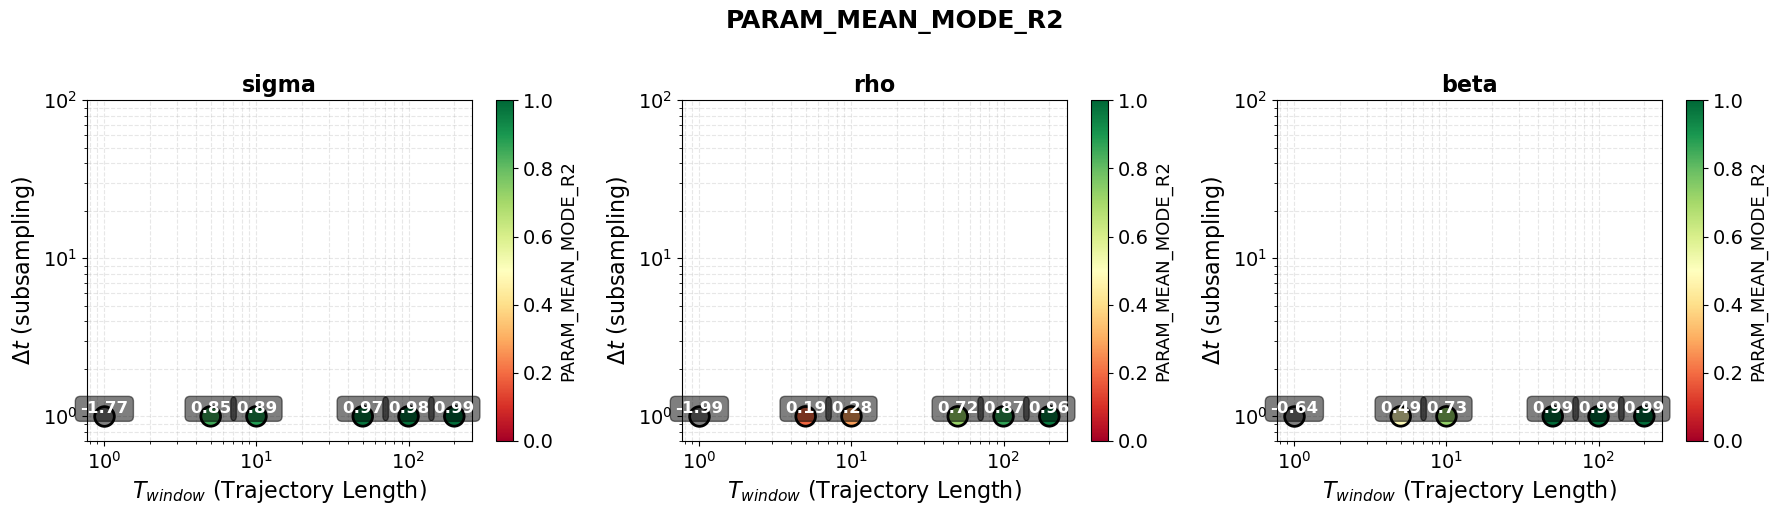

In [10]:
# Example usage
plot_multiple_metrics(
    metrics_dict=metrics,
    metric_paths=[
        # 'PARAM_r2',
        'PARAM_mean_mode_r2',
        # 'PARAM_mode_metrics.mode_0.r2',
        # 'PARAM_mode_metrics.mode_1.r2',
        # 'PARAM_rmse',
    ],
    save_path='./results/plots/lstm',
    include_avg=True
)

In [ ]:
keys
keys = ['study1_temporal_extent_T1_dt1_easy',
 'study1_temporal_extent_T5_dt1_easy',
 'study1_temporal_extent_T10_dt1_easy',
 'study1_temporal_extent_T50_dt1_easy',
 'study1_temporal_extent_T100_dt1_easy',
 'study1_temporal_extent_T200_dt1_easy',
 'study2a_sampling_short_T200_dt2_easy',
 'study2a_sampling_short_T200_dt5_easy',
 'study2a_sampling_short_T200_dt10_easy',
 'study2a_sampling_short_T200_dt20_easy',
 'study2a_sampling_short_T200_dt50_easy',
 'study2b_sampling_long_T1000_dt5_easy']

In [11]:
import re
from IPython.display import display, Math

experiment_key = "study"
pat_dt = re.compile(r"dt(\d+)")
pat_T  = re.compile(r"T(\d+)")

for key in (keys):
    if experiment_key in key:
        m_dt = pat_dt.search(key)
        m_T  = pat_T.search(key)
        if not (m_dt and m_T):
            continue
        dt = int(m_dt.group(1))
        T  = int(m_T.group(1))
        npoints = T // dt

        rho   = metrics[key]['rho_mean_mode_r2']
        sigma = metrics[key]['sigma_mean_mode_r2']
        beta  = metrics[key]['beta_mean_mode_r2']
        keypart = key.split('_')[1]
        display(Math(
            fr"\text{{Experiment }}{keypart}(T={T},\,\Delta t={dt}, n\Delta t = {npoints}):\quad "
            fr"R^2_{{\rho}}={rho:.2f},\; R^2_{{\sigma}}={sigma:.2f},\; R^2_{{\beta}}={beta:.2f}"
        ))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

📊 Metrics table saved to: plots/tables/lorenz 63_metrics_summary_redo.png
📄 PDF saved to: plots/tables/lorenz 63_metrics_summary_redo.pdf


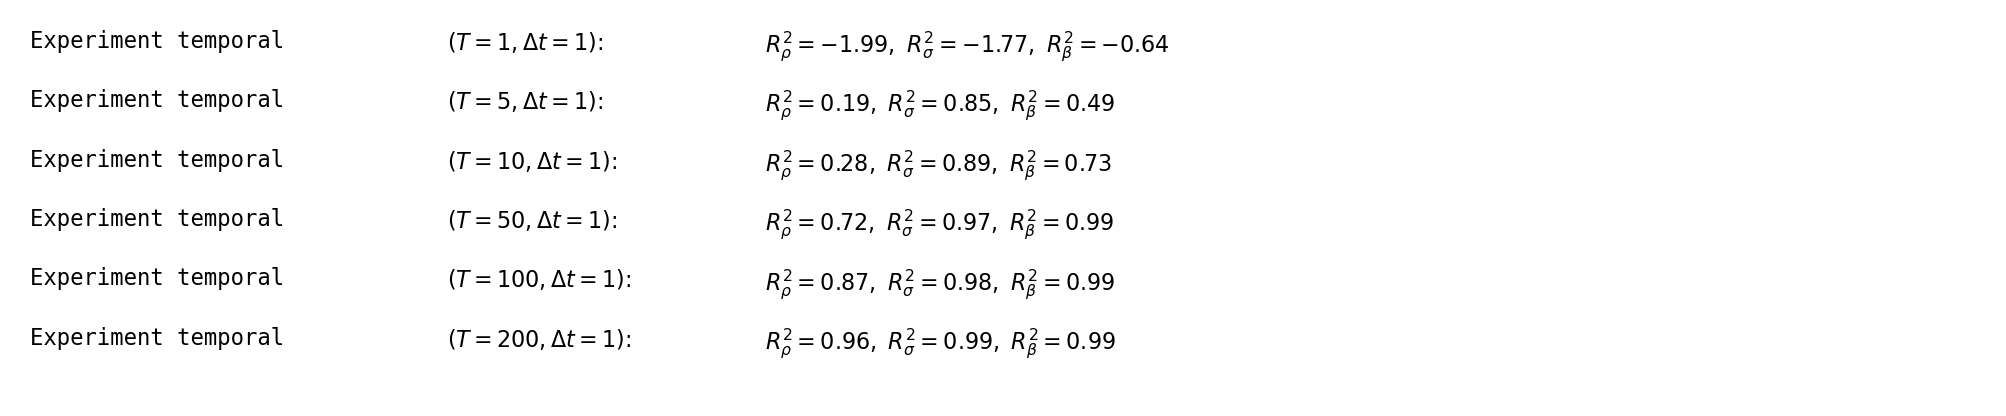

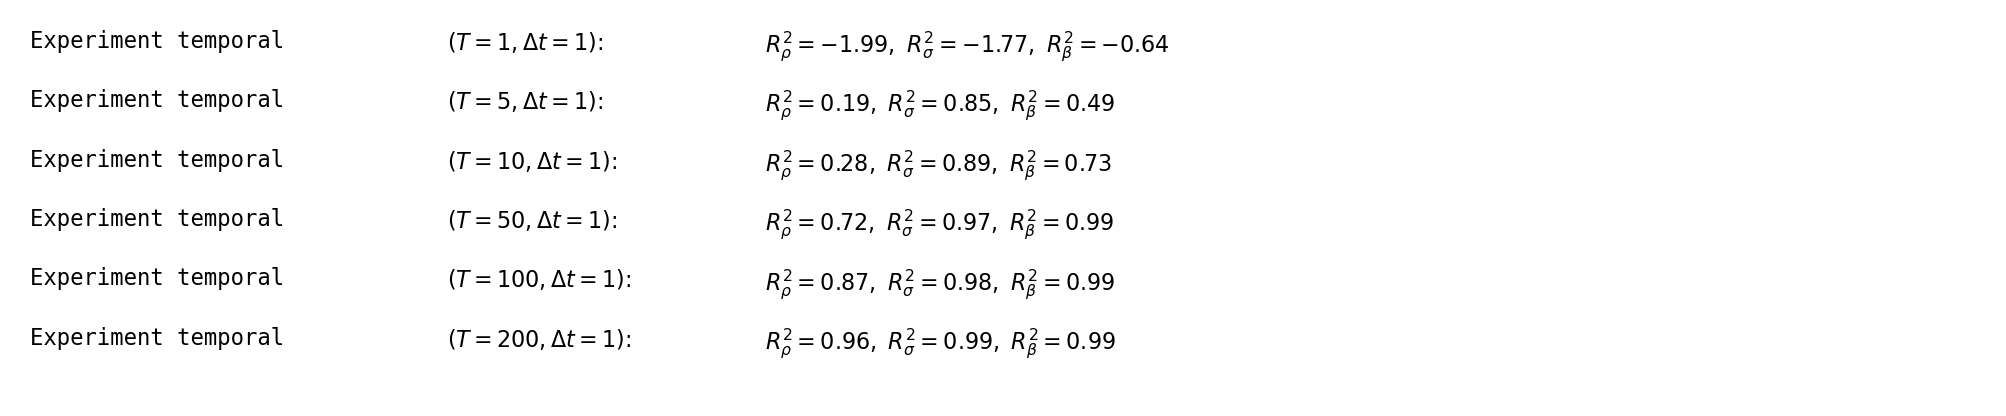

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re

def save_metrics_table_to_pdf(metrics, keys, experiment_key="study", 
                               output_dir='plots/tables', 
                               filename='metrics_summary'):
    """
    Save metrics as a styled table to PDF with proper column alignment.
    
    Parameters:
    -----------
    metrics : dict
        Dictionary containing metrics for each key
    keys : list
        List of experiment keys to analyze
    experiment_key : str
        Filter for experiment keys (e.g., "study")
    output_dir : str
        Directory to save the PDF
    filename : str
        Base name for output file
    """
    pat_dt = re.compile(r"dt(\d+)")
    pat_T  = re.compile(r"T(\d+)")
    
    # Collect all results
    results = []
    
    for key in keys:
        if experiment_key in key:
            m_dt = pat_dt.search(key)
            m_T  = pat_T.search(key)
            if not (m_dt and m_T):
                continue
            dt = int(m_dt.group(1))
            T  = int(m_T.group(1))
            npoints = T // dt
            
            rho   = metrics[key]['rho_mean_mode_r2']
            sigma = metrics[key]['sigma_mean_mode_r2']
            beta  = metrics[key]['beta_mean_mode_r2']
            
            # Extract experiment type (temporal, sampling, etc.)
            key_parts = key.split('_')
            if len(key_parts) > 1:
                exp_type = key_parts[1]
            else:
                exp_type = "unknown"
            
            results.append({
                'exp_type': exp_type,
                'T': T,
                'dt': dt,
                'npoints': npoints,
                'rho': rho,
                'sigma': sigma,
                'beta': beta,
                'full_key': key
            })
    
    if not results:
        print("⚠️  No matching keys found!")
        return
    
    # Create figure with appropriate size
    fig_height = max(len(results) * 0.6 + 0.5, 4)
    fig, ax = plt.subplots(figsize=(20, fig_height))
    ax.axis('off')
    
    # Create text lines with FIXED column positions
    y_position = 0.95
    y_step = 0.9 / len(results) if results else 0.1
    
    # Define fixed x positions for each column
    x_col1 = 0.01  # Experiment name
    x_col2 = 0.22  # Parameters (T, Δt)
    x_col3 = 0.38  # R² values
    
    for result in results:
        exp_type = result['exp_type']
        T = result['T']
        dt = result['dt']
        npoints = result['npoints']
        rho = result['rho']
        sigma = result['sigma']
        beta = result['beta']
        
        # Column 1: Experiment type with T for sampling experiments
        if exp_type == 'sampling':
            col1_text = f"Experiment {exp_type} (T={T})"
        else:
            col1_text = f"Experiment {exp_type}"
        
        # Column 2: Parameters
        col2_text = f"$(T = {T:>4}, \\Delta t = {dt:>2})$:"
        
        # Column 3: R² values
        col3_text = f"$R^2_{{\\rho}} = {rho:>5.2f}, \,\, R^2_{{\\sigma}} = {sigma:.2f}, \, \, R^2_{{\\beta}} = {beta:.2f}$"
        
        # Plot each column at fixed x position
        ax.text(x_col1, y_position, col1_text, transform=ax.transAxes,
                fontsize=16, verticalalignment='top', 
                family='monospace', fontstyle='normal',
                ha='left')
        
        ax.text(x_col2, y_position, col2_text, transform=ax.transAxes,
                fontsize=16, verticalalignment='top',
                ha='left')
        
        ax.text(x_col3, y_position, col3_text, transform=ax.transAxes,
                fontsize=16, verticalalignment='top',
                ha='left')
        
        y_position -= y_step
    
    plt.tight_layout(pad=0.5)
    
    # Save figure
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    
    # Save as PNG
    png_path = Path(output_dir) / f'{filename}_redo.png'
    plt.savefig(png_path, dpi=300, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    print(f"📊 Metrics table saved to: {png_path}")
    
    # Save as PDF
    pdf_path = Path(output_dir) / f'{filename}_redo.pdf'
    plt.savefig(pdf_path, bbox_inches='tight', facecolor='white')
    print(f"📄 PDF saved to: {pdf_path}")
    
    plt.show()
    plt.close()
    
    return fig

# Usage:
save_metrics_table_to_pdf(
    metrics=metrics,
    keys=keys,
    experiment_key="study",
    output_dir='plots/tables',
    filename='lorenz 63_metrics_summary'
)

In [ ]:
keys

['study1_temporal_extent_T1_dt1_easy',
 'study1_temporal_extent_T5_dt1_easy',
 'study1_temporal_extent_T10_dt1_easy',
 'study1_temporal_extent_T50_dt1_easy',
 'study1_temporal_extent_T100_dt1_easy',
 'study1_temporal_extent_T200_dt1_easy',
 'study2a_sampling_short_T200_dt2_easy',
 'study2a_sampling_short_T200_dt5_easy',
 'study2a_sampling_short_T200_dt10_easy',
 'study2a_sampling_short_T200_dt20_easy',
 'study2a_sampling_short_T200_dt50_easy',
 'study2b_sampling_long_T1000_dt5_easy',
 'study2b_sampling_long_T1000_dt10_easy',
 'study2b_sampling_long_T1000_dt20_easy',
 'study2b_sampling_long_T1000_dt50_easy',
 'study3_summaries_T50_dt1_easy_avg',
 'study3_summaries_T100_dt1_easy_avg',
 'study3_summaries_T500_dt1_easy_avg',
 'study3_summaries_T1000_dt1_easy_avg']

📊 Plot saved to: plots/tables/r2_trajectory_analysis_T10_rho.png
📄 PDF saved to: plots/tables/r2_trajectory_analysis_T10_rho.pdf


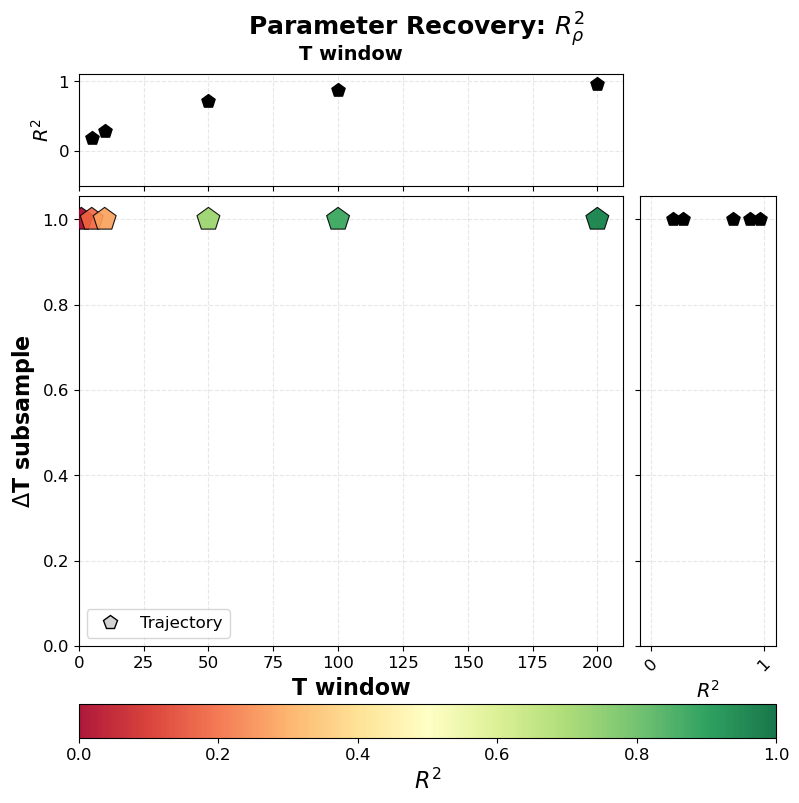

📊 Plot saved to: plots/tables/r2_trajectory_analysis_T10_sigma.png
📄 PDF saved to: plots/tables/r2_trajectory_analysis_T10_sigma.pdf


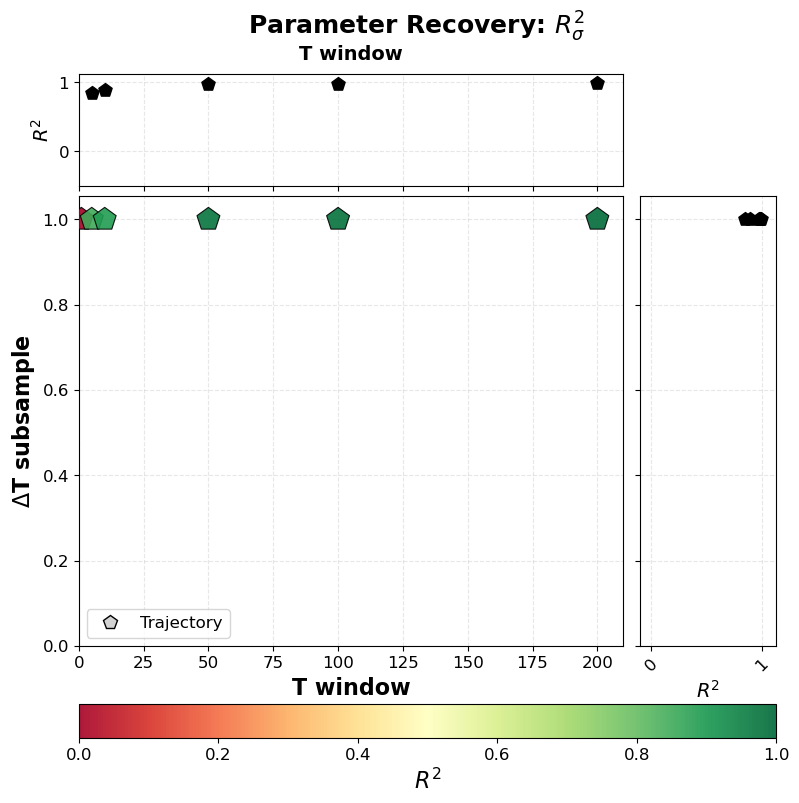

📊 Plot saved to: plots/tables/r2_trajectory_analysis_T10_beta.png
📄 PDF saved to: plots/tables/r2_trajectory_analysis_T10_beta.pdf


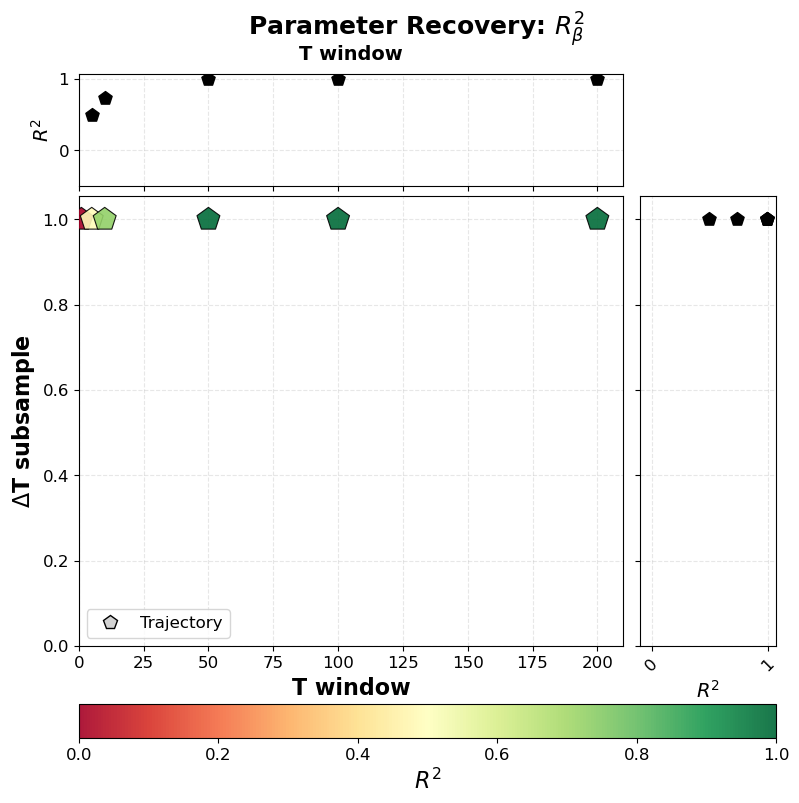

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from pathlib import Path
import re

def create_r2_trajectory_plot(metrics, keys, experiment_key="study",
                              param='rho', output_dir='plots/tables',
                              filename='r2_trajectory_analysis'):
    """
    Create a 2D plot showing R² as function of T window and Δt subsample,
    with marginal distributions on the sides.
    Different markers for regular vs summary experiments.
    
    Parameters:
    -----------
    metrics : dict
        Dictionary containing metrics for each key
    keys : list
        List of experiment keys to analyze
    experiment_key : str
        Filter for experiment keys (e.g., "study")
    param : str
        Which parameter to plot ('rho', 'sigma', or 'beta')
    output_dir : str
        Directory to save the PDF
    filename : str
        Base name for output file
    """
    pat_dt = re.compile(r"dt(\d+)")
    pat_T  = re.compile(r"T(\d+)")
    
    # Collect all results
    results = []
    
    for key in keys:
        if experiment_key in key:
            m_dt = pat_dt.search(key)
            m_T  = pat_T.search(key)
            if not (m_dt and m_T):
                continue
            dt = int(m_dt.group(1))
            T  = int(m_T.group(1))
            
            # Get R² for specified parameter
            r2_key = f'{param}_mean_mode_r2'
            if r2_key in metrics[key]:
                r2 = metrics[key][r2_key]
            else:
                continue
            
            # Check if this is a summary experiment
            is_summary = 'summaries' in key or 'summary' in key
            
            results.append({
                'T': T,
                'dt': dt,
                'r2': r2,
                'key': key,
                'is_summary': is_summary
            })
    
    if not results:
        print("⚠️  No matching keys found!")
        return
    
    # Separate regular and summary experiments
    regular_results = [r for r in results if not r['is_summary']]
    summary_results = [r for r in results if r['is_summary']]
    
    # Extract arrays for regular experiments
    T_reg = np.array([r['T'] for r in regular_results])
    dt_reg = np.array([r['dt'] for r in regular_results])
    r2_reg = np.array([r['r2'] for r in regular_results])
    
    # Extract arrays for summary experiments
    T_sum = np.array([r['T'] for r in summary_results]) if summary_results else np.array([])
    dt_sum = np.array([r['dt'] for r in summary_results]) if summary_results else np.array([])
    r2_sum = np.array([r['r2'] for r in summary_results]) if summary_results else np.array([])
    
    # Combine all R² values for color normalization
    all_r2 = np.concatenate([r2_reg, r2_sum]) if len(r2_sum) > 0 else r2_reg
    
    # Create figure with GridSpec for main plot + marginals + colorbar at bottom
    fig = plt.figure(figsize=(9, 8))
    
    # Create grid with different hspace for different row pairs
    from matplotlib.gridspec import GridSpec
    gs = GridSpec(3, 2, figure=fig, 
                  width_ratios=[4, 1], 
                  height_ratios=[1, 4, 0.3],
                  hspace=0.05,  # Keep original tight spacing
                  wspace=0.05)
    
    # Main plot (middle left)
    ax_main = fig.add_subplot(gs[1, 0])
    
    # Top marginal (top left)
    ax_top = fig.add_subplot(gs[0, 0], sharex=ax_main)
    
    # Right marginal (middle right)
    ax_right = fig.add_subplot(gs[1, 1], sharey=ax_main)
    
    # Colorbar axis (bottom, spanning both columns)
    ax_cbar = fig.add_subplot(gs[2, :])
    
    # Manually adjust the position of the colorbar to add space
    pos_cbar = ax_cbar.get_position()
    pos_cbar.y0 = pos_cbar.y0 - 0.06  # Move colorbar down
    pos_cbar.y1 = pos_cbar.y1 - 0.06
    ax_cbar.set_position(pos_cbar)
    
    # Color mapping for R² - START AT 0
    vmin = 0  # Force colorbar to start at 0
    vmax = max(1.0, all_r2.max())  # At least go to 1.0, or higher if needed
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap = cm.RdYlGn  # Red (low) -> Yellow -> Green (high)
    
    
    # Main scatter plot - Summary experiments (circles instead of stars)
    if len(summary_results) > 0:
        scatter_sum = ax_main.scatter(T_sum, dt_sum, c=r2_sum, s=350, 
                                      cmap=cmap, norm=norm, 
                                      edgecolors='black', linewidths=0.8,  # Thinner edges
                                      marker='o', alpha=0.9, zorder=4,  # Changed to 'o' for circle
                                      label='Summary')
    
    # Main scatter plot - Regular experiments (pentagons)
    if len(regular_results) > 0:
        scatter_reg = ax_main.scatter(T_reg, dt_reg, c=r2_reg, s=300, 
                                      cmap=cmap, norm=norm, 
                                      edgecolors='black', linewidths=0.8,  # Thinner edges
                                      marker='p', alpha=0.9, zorder=3,
                                      label='Trajectory')
    
    # Formatting main plot - START AXES AT 0
    ax_main.set_xlabel('T window', fontsize=16, fontweight='bold')
    ax_main.set_ylabel(r'$\Delta$T subsample', fontsize=16, fontweight='bold')
    ax_main.grid(True, alpha=0.3, linestyle='--', zorder=1)
    ax_main.tick_params(labelsize=12)
    
    # Create custom legend with no color (gray fills)
    from matplotlib.lines import Line2D
    legend_elements = []
    if len(regular_results) > 0:
        legend_elements.append(Line2D([0], [0], marker='p', color='w', 
                                     markerfacecolor='lightgray', markeredgecolor='black',
                                     markersize=10, label='Trajectory', linewidth=0))
    if len(summary_results) > 0:
        legend_elements.append(Line2D([0], [0], marker='o', color='w', 
                                     markerfacecolor='lightgray', markeredgecolor='black',
                                     markersize=10, label='Summary', linewidth=0))
    ax_main.legend(handles=legend_elements, fontsize=12, loc='best')
    
    # Set x-axis to start at 0
    ax_main.set_xlim(left=0)
    # Set y-axis to start at 0
    ax_main.set_ylim(bottom=0)
    
    # Add colorbar at the bottom
    scatter_for_cbar = scatter_reg if len(regular_results) > 0 else scatter_sum
    cbar = plt.colorbar(scatter_for_cbar, cax=ax_cbar, orientation='horizontal')
    cbar.set_label(f'$R^2$', fontsize=16, fontweight='bold')
    cbar.ax.tick_params(labelsize=12)
    
    # Top marginal: R² vs T window - SHOW BOTH REGULAR AND SUMMARY
    # Smaller symbols for 1D plots
    for result in regular_results:
        ax_top.scatter(result['T'], result['r2'], s=100, marker='p',  # Reduced from 300
                      edgecolors='black', linewidths=1, color='black', zorder=3)
    
    for result in summary_results:
        ax_top.scatter(result['T'], result['r2'], s=120, marker='o',  # Reduced from 400, changed to circle
                      edgecolors='black', linewidths=1, color='black', zorder=4)
    
    # Add text annotation to explain what's shown
    # Find most common dt value for regular experiments
    # if len(regular_results) > 0:
    #     unique_dt_reg, counts_dt_reg = np.unique(dt_reg, return_counts=True)
    #     most_common_dt = unique_dt_reg[np.argmax(counts_dt_reg)]
    #     ax_top.text(0.98, 0.95, f'varying T, fixed $\\Delta T$', 
    #                transform=ax_top.transAxes, va='top', ha='right',
    #                fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))
    
    ax_top.set_ylabel('$R^2$', fontsize=14, fontweight='bold')
    ax_top.tick_params(axis='x', labelbottom=False, labelsize=12)
    ax_top.tick_params(axis='y', labelsize=12)
    ax_top.grid(True, alpha=0.3, linestyle='--', zorder=1)
    ax_top.set_title('T window', fontsize=14, fontweight='bold', pad=10)
    
    # Set y-axis to start at 0 for top marginal
    ax_top.set_ylim(bottom=-0.5)
    
    # Right marginal: R² vs Δt - SHOW BOTH REGULAR AND SUMMARY
    # Smaller symbols for 1D plots
    
    for result in summary_results:
        ax_right.scatter(result['r2'], result['dt'], s=120, marker='o',  # Reduced from 400, changed to circle
                        edgecolors='black', linewidths=1, color='black', zorder=4)
    for result in regular_results:
        ax_right.scatter(result['r2'], result['dt'], s=100, marker='p',  # Reduced from 300
                        edgecolors='black', linewidths=1, color='black', zorder=3)
    
    # # Add text annotation to explain what's shown
    # if len(regular_results) > 0:
    #     unique_T_reg, counts_T_reg = np.unique(T_reg, return_counts=True)
    #     most_common_T = unique_T_reg[np.argmax(counts_T_reg)]
    #     ax_right.text(0.95, 0.02, f'varying $\\Delta T$, fixed T', 
    #                  transform=ax_right.transAxes, va='bottom', ha='right',
    #                  fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7),
    #                  rotation=0)
    
    ax_right.set_xlabel('$R^2$', fontsize=14, fontweight='bold')
    ax_right.tick_params(axis='y', labelleft=False, labelsize=12)
    ax_right.tick_params(axis='x', labelsize=12)
    ax_right.grid(True, alpha=0.3, linestyle='--', zorder=1)
    
    # Set x-axis to start at 0 for right marginal
    ax_right.set_xlim(left=-0.1)
    
    # Rotate x-axis labels for right marginal
    ax_right.tick_params(axis='x', rotation=45)
    
    # Add parameter label
    param_symbol = {'rho': 'ρ', 'sigma': 'σ', 'beta': 'β'}[param]
    fig.suptitle(f'Parameter Recovery: $R^2_{{{param_symbol}}}$', 
                 fontsize=18, fontweight='bold', y=0.96)
    
    # Save figure
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    
    # Save as PNG
    png_path = Path(output_dir) / f'{filename}_{param}.png'
    plt.savefig(png_path, dpi=300, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    print(f"📊 Plot saved to: {png_path}")
    
    # Save as PDF
    pdf_path = Path(output_dir) / f'{filename}_{param}.pdf'
    plt.savefig(pdf_path, bbox_inches='tight', facecolor='white')
    print(f"📄 PDF saved to: {pdf_path}")
    
    plt.show()
    plt.close()
    
    return fig

# Usage: Create plots for each parameter
for param in ['rho', 'sigma', 'beta']:
    create_r2_trajectory_plot(
        metrics=metrics,
        keys=keys,
        experiment_key="study",
        param=param,
        output_dir='plots/tables',
        filename='r2_trajectory_analysis_T10'
    )

In [14]:
import re, matplotlib.pyplot as plt

experiment_key = "study2b_sampling_long"
pat_dt = re.compile(r"dt(\d+)")
pat_T  = re.compile(r"T(\d+)")

lines = []
for key in sorted(keys):
    if experiment_key in key:
        dt = int(pat_dt.search(key).group(1))
        T  = int(pat_T.search(key).group(1))
        rho   = metrics[key]['rho_mean_mode_r2']
        sigma = metrics[key]['sigma_mean_mode_r2']
        beta  = metrics[key]['beta_mean_mode_r2']
        lines.append(
            rf"\text{{Experiment }}(T={T},\,\Delta t={dt}):\;"
            rf"R^2_{{\rho}}={rho:.2f},\; R^2_{{\sigma}}={sigma:.2f},\; R^2_{{\beta}}={beta:.2f}"
        )

# Make a tall figure with one math line per row
plt.rcParams["text.usetex"] = False  # set True if you have LaTeX installed
fig_h = 0.6 + 0.4*len(lines)
fig = plt.figure(figsize=(10, fig_h))
ax = fig.add_axes([0,0,1,1]); ax.set_axis_off()

for i, s in enumerate(lines):
    y = 1 - (i+1)/(len(lines)+1)
    ax.text(0.02, y, f"${s}$", ha="left", va="center", fontsize=18)

fig.savefig(f"{experiment_key}_r2_summary_T10.png", dpi=300, bbox_inches="tight", transparent=True)
plt.close(fig)




In [ ]:
metrics.keys()

dict_keys(['study1_temporal_extent_T1_dt1_easy', 'study1_temporal_extent_T5_dt1_easy', 'study1_temporal_extent_T10_dt1_easy', 'study1_temporal_extent_T50_dt1_easy', 'study1_temporal_extent_T100_dt1_easy', 'study1_temporal_extent_T200_dt1_easy', 'study1_temporal_extent_T500_dt1_easy', 'study1_temporal_extent_T1000_dt1_easy', 'study2a_sampling_short_T200_dt1_easy', 'study2a_sampling_short_T200_dt2_easy', 'study2a_sampling_short_T200_dt5_easy', 'study2a_sampling_short_T200_dt10_easy', 'study2a_sampling_short_T200_dt20_easy', 'study2a_sampling_short_T200_dt50_easy', 'study2b_sampling_long_T1000_dt1_easy', 'study2b_sampling_long_T1000_dt5_easy', 'study2b_sampling_long_T1000_dt10_easy', 'study2b_sampling_long_T1000_dt20_easy', 'study2b_sampling_long_T1000_dt50_easy', 'study3_summaries_T50_dt1_easy_avg', 'study3_summaries_T100_dt1_easy_avg', 'study3_summaries_T500_dt1_easy_avg', 'study3_summaries_T1000_dt1_easy_avg'])

# Below is the code for corner plot


# the block below computes several metrics! will go back to it later!

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
from scipy.stats import gaussian_kde

def _kde1d(x, grid=None, bw=None):
    x = np.asarray(x).ravel()
    if grid is None:
        lo, hi = np.percentile(x, [0.5, 99.5])
        grid = np.linspace(lo, hi, 300)
    kde = gaussian_kde(x, bw_method=bw)
    return grid, kde(grid)

def _kde2d(x, y, xgrid=None, ygrid=None, bw=None):
    xy = np.vstack([x.ravel(), y.ravel()])
    kde = gaussian_kde(xy, bw_method=bw)
    if xgrid is None:
        xgrid = np.linspace(*np.percentile(x, [0.5, 99.5]), 150)
    if ygrid is None:
        ygrid = np.linspace(*np.percentile(y, [0.5, 99.5]), 150)
    xx, yy = np.meshgrid(xgrid, ygrid)
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    return xx, yy, zz

def compare_posteriors_panels(nflow_samples, true_samples, labels=None,
                              truths=None, figsize=8, fontsize = 16,
                              tick_labelsize=16,savepath=None,
                              levels=(0.68, 0.95), bins=40, hexbin_gridsize=35):
    """
    Minimalist joint view:
      - diagonal: 1D KDEs (true vs flow)
      - lower-tri: hexbin (flow) + contour (true)
    """
    nflow_samples = np.asarray(nflow_samples)
    true_samples  = np.asarray(true_samples)
    assert nflow_samples.shape[1] == true_samples.shape[1], "Dim mismatch."

    D = nflow_samples.shape[1]
    if labels is None:
        labels = [f"θ{j+1}" for j in range(D)]

    fig = plt.figure(figsize=(figsize, figsize))
    gs = GridSpec(D, D, figure=fig, wspace=0.15, hspace=0.25)

    contour_levels = 5

    for i in range(D):
        for j in range(D):
            ax = fig.add_subplot(gs[i, j])
            if i == j:
                # --- 1D KDEs ---
                x_true = true_samples[:, j]
                x_flow = nflow_samples[:, j]
                gx, f_true = _kde1d(x_true)
                gx2, f_flow = _kde1d(x_flow, grid=gx)

                ax.plot(gx, f_true, color='C0', lw=2, label="True")
                ax.fill_between(gx, 0, f_true, color='C0', alpha=0.2)
                ax.plot(gx2, f_flow, color='C1', lw=2, ls="--", label="Flow")
                ax.fill_between(gx2, 0, f_flow, color='C1', alpha=0.25)

                if truths is not None:
                    ax.axvline(truths[j], color='black', ls='--', lw=1.5, alpha=0.8)

                if j == 0:
                    ax.set_ylabel("density", fontsize=fontsize)
                else:
                    ax.set_yticks([])
                
                if i == D-1:  # Only bottom row
                    ax.set_xlabel(labels[j], fontsize=fontsize, fontweight='bold')
                else:
                    ax.set_xticks([])

            elif i > j:
                # --- 2D lower triangle: hexbin (flow) + KDE contours (true) ---
                x_f, y_f = nflow_samples[:, j], nflow_samples[:, i]
                x_t, y_t = true_samples[:, j], true_samples[:, i]

                # # hexbin for flow
                # hb = ax.hexbin(x_f, y_f, gridsize=hexbin_gridsize, 
                #               cmap='Oranges', mincnt=1, linewidths=0.0, alpha=0.86)
                hb = ax.hexbin(x_f, y_f, gridsize=hexbin_gridsize, 
                cmap='Reds', mincnt=1, linewidths=0.0, alpha=0.8)
                # KDE contours for true
                xx, yy, zz = _kde2d(x_t, y_t)
                cs = ax.contour(xx, yy, zz, levels=contour_levels, 
                               colors='blue', linewidths=1.25, alpha=0.8)

                if truths is not None:
                    ax.scatter(truths[j], truths[i], s=80, marker="x", 
                              color='red', linewidths=2.5, zorder=10)

                if j == 0:
                    ax.set_ylabel(labels[i], fontsize=fontsize, fontweight='bold')
                else:
                    ax.set_yticks([])
                if i == D-1:
                    ax.set_xlabel(labels[j], fontsize=fontsize, fontweight='bold')
                else:
                    ax.set_xticks([])

            else:
                # upper triangle left blank
                ax.axis("off")
            ax.tick_params(axis='both', which='major', labelsize=tick_labelsize)

    # Legend – put it in upper-right corner panel (blank area)
    if D > 1:
        ax_legend = fig.add_subplot(gs[0, -1])
        handles = [
            plt.Line2D([0],[0], color="blue", lw=2, label="True"),
            plt.Line2D([0],[0], color="C1", lw=2, ls="--", label="Flow (1D)"),
            Rectangle((0,0), 1, 1, fc="red", alpha=0.5, ec="none", label="Flow (hexbin)"),
        ]
        if truths is not None:
            handles.append(plt.Line2D([0],[0], marker="x", color='red', 
                                     ls='', markersize=10, markeredgewidth=2, 
                                     label="True value"))
        ax_legend.legend(handles=handles, loc="center", frameon=True, fontsize=fontsize+3)
        ax_legend.axis("off")

    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    
    plt.tight_layout()
    return fig

In [ ]:
import numpy as np
import pandas as pd
import os
import json
from typing import Dict
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# HELPER FUNCTION TO CONVERT NUMPY TYPES TO NATIVE PYTHON
# ============================================================

def convert_to_serializable(obj):
    """
    Recursively convert numpy types to native Python types for JSON serialization
    """
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, (np.float32, np.float64)):
        return float(obj)
    elif isinstance(obj, (np.int32, np.int64)):
        return int(obj)
    elif isinstance(obj, dict):
        return {key: convert_to_serializable(val) for key, val in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_serializable(item) for item in obj]
    else:
        return obj


# ============================================================
# INTEGRATED METRICS COMPUTATION WITH YOUR PIPELINE
# ============================================================

def compute_metrics_for_all_models(models_dict, 
                                   prior_samples=None,
                                   save_dir='./results/metrics'):
    """
    Compute all metrics for all models in models_dict
    
    Args:
        models_dict: Dictionary with model results from your pipeline
        prior_samples: (N_prior, 3) normalized prior samples [0,1] range
        save_dir: Where to save results
    """
    
    os.makedirs(save_dir, exist_ok=True)
    
    # Initialize evaluator
    evaluator = PosteriorMetrics(param_names=['sigma', 'rho', 'beta'])
    
    all_metrics = {}
    all_dataframes = []
    
    for key, model_data in models_dict.items():
        print(f"\n{'='*80}")
        print(f"Evaluating: {key}")
        print(f"{'='*80}")
        
        # Extract data
        theta_true = model_data['params_true']          # (N_test, 3)
        posterior_samples = model_data['params_generated']  # (N_test, N_samples, 3)
        
        # Ensure they are numpy arrays (not torch tensors)
        if hasattr(theta_true, 'numpy'):
            theta_true = theta_true.numpy()
        if hasattr(posterior_samples, 'numpy'):
            posterior_samples = posterior_samples.numpy()
        
        # Convert to float64 to avoid serialization issues
        theta_true = np.array(theta_true, dtype=np.float64)
        posterior_samples = np.array(posterior_samples, dtype=np.float64)
        
        print(f"  True params shape: {theta_true.shape}")
        print(f"  Posterior samples shape: {posterior_samples.shape}")
        
        # Compute log probabilities (optional - requires model forward pass)
        log_probs = None  # Set to None if not computing
        
        # Compute all metrics
        try:
            metrics = evaluator.compute_all_metrics(
                theta_true=theta_true,
                posterior_samples=posterior_samples,
                prior_samples=prior_samples,
                log_probs=log_probs
            )
        except Exception as e:
            print(f"ERROR computing metrics for {key}: {e}")
            import traceback
            traceback.print_exc()
            continue
        
        # Add experimental metadata
        metrics['metadata'] = {
            'key': key,
            'T_window': int(model_data['T_window']),
            'dt_subsample': int(model_data['dt_subsample']),
            'T_obs_time_units': float(model_data['T_window'] * 0.01),
            'delta_t': float(model_data['dt_subsample'] * 0.01),
            'L_points': int(model_data['T_window'] // model_data['dt_subsample']),
            'run_name': str(model_data['run_name'])
        }
        
        # Print summary
        evaluator.print_metrics_summary(metrics)
        
        # Save individual CSV
        model_save_dir = os.path.join(save_dir, key)
        os.makedirs(model_save_dir, exist_ok=True)
        
        df = evaluator.save_metrics_to_csv(
            metrics,
            os.path.join(model_save_dir, 'metrics_per_parameter.csv')
        )
        
        # Add metadata to dataframe
        for col in ['T_window', 'dt_subsample', 'T_obs_time_units', 'delta_t', 'L_points']:
            df[col] = metrics['metadata'][col]
        df['experiment_key'] = key
        
        all_dataframes.append(df)
        all_metrics[key] = metrics
        
        # Save full metrics as JSON with proper serialization
        metrics_json = convert_to_serializable(metrics)
        
        json_path = os.path.join(model_save_dir, 'metrics_full.json')
        try:
            with open(json_path, 'w') as f:
                json.dump(metrics_json, f, indent=2)
            print(f"  ✓ Saved full metrics to {json_path}")
        except Exception as e:
            print(f"  ✗ Error saving JSON for {key}: {e}")
    
    # Combine all dataframes for cross-experiment comparison
    if all_dataframes:
        combined_df = pd.concat(all_dataframes, ignore_index=True)
        combined_csv = os.path.join(save_dir, 'all_experiments_metrics.csv')
        combined_df.to_csv(combined_csv, index=False)
        print(f"\n✓ Saved combined metrics to {combined_csv}")
    else:
        print("\n✗ No metrics computed successfully")
        combined_df = pd.DataFrame()
    
    return all_metrics, combined_df


# ============================================================
# ANALYSIS FUNCTIONS FOR YOUR EXPERIMENTS
# ============================================================

def analyze_study1_results(combined_df, save_dir='./results/plots'):
    """
    Analyze Study 1: Effect of temporal extent
    """
    os.makedirs(save_dir, exist_ok=True)
    
    if len(combined_df) == 0:
        print("No data to analyze")
        return
    
    # Filter Study 1 data (dt_subsample = 1)
    study1_data = combined_df[combined_df['dt_subsample'] == 1].copy()
    
    if len(study1_data) == 0:
        print("No Study 1 data found (dt_subsample=1)")
        return
    
    # Plot posterior variance vs T_obs for each parameter
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    params = ['sigma', 'rho', 'beta']
    
    for i, param in enumerate(params):
        param_data = study1_data[study1_data['parameter'] == param].sort_values('T_obs_time_units')
        
        if len(param_data) == 0:
            continue
        
        axes[i].plot(param_data['T_obs_time_units'], 
                    param_data['posterior_variance'],
                    marker='o', linewidth=2, markersize=8)
        
        axes[i].set_xlabel('Temporal Extent $T_{obs}$ (time units)', fontsize=12)
        axes[i].set_ylabel('Posterior Variance', fontsize=12)
        axes[i].set_title(f'Parameter: {param}', fontsize=14, fontweight='bold')
        axes[i].set_xscale('log')
        axes[i].set_yscale('log')
        axes[i].grid(True, alpha=0.3)
        
        # Add reference lines for timescales
        axes[i].axvline(1.0, color='gray', linestyle='--', alpha=0.5, linewidth=1.5, label='~1 orbit')
        axes[i].axvline(5.0, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='~1 switch')
        axes[i].legend(fontsize=10)
    
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'study1_variance_vs_T_obs.png'), dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✓ Saved Study 1 variance plot")
    
    # Plot coverage vs T_obs
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    for i, param in enumerate(params):
        param_data = study1_data[study1_data['parameter'] == param].sort_values('T_obs_time_units')
        
        if len(param_data) == 0:
            continue
        
        axes[i].plot(param_data['T_obs_time_units'], 
                    param_data['coverage_95'],
                    marker='o', linewidth=2, markersize=8, label='95% CI')
        axes[i].plot(param_data['T_obs_time_units'], 
                    param_data['coverage_68'],
                    marker='s', linewidth=2, markersize=8, label='68% CI')
        
        axes[i].axhline(0.95, color='black', linestyle='--', alpha=0.5, label='Ideal 95%')
        axes[i].axhline(0.68, color='gray', linestyle='--', alpha=0.5, label='Ideal 68%')
        
        axes[i].set_xlabel('Temporal Extent $T_{obs}$ (time units)', fontsize=12)
        axes[i].set_ylabel('Empirical Coverage', fontsize=12)
        axes[i].set_title(f'Parameter: {param}', fontsize=14, fontweight='bold')
        axes[i].set_xscale('log')
        axes[i].set_ylim([0, 1.05])
        axes[i].grid(True, alpha=0.3)
        axes[i].legend(fontsize=10)
    
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'study1_coverage_vs_T_obs.png'), dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✓ Saved Study 1 coverage plot")


def analyze_study2_results(combined_df, save_dir='./results/plots'):
    """
    Analyze Study 2: Effect of sampling resolution
    """
    os.makedirs(save_dir, exist_ok=True)
    
    if len(combined_df) == 0:
        print("No data to analyze")
        return
    
    # Study 2a: T_window = 200 (T_obs = 2)
    study2a_data = combined_df[combined_df['T_window'] == 200].copy()
    
    # Study 2b: T_window = 1000 (T_obs = 10)
    study2b_data = combined_df[combined_df['T_window'] == 1000].copy()
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    params = ['sigma', 'rho', 'beta']
    
    for row, (data, label) in enumerate([(study2a_data, '$T_{obs}=2$'), 
                                          (study2b_data, '$T_{obs}=10$')]):
        if len(data) == 0:
            continue
            
        for i, param in enumerate(params):
            param_data = data[data['parameter'] == param].sort_values('delta_t')
            
            if len(param_data) == 0:
                continue
            
            axes[row, i].plot(param_data['delta_t'], 
                            param_data['posterior_variance'],
                            marker='o', linewidth=2, markersize=8)
            
            if row == 0:
                axes[row, i].set_title(f'Parameter: {param}', fontsize=14, fontweight='bold')
            
            axes[row, i].set_xlabel('Sampling Interval $\\Delta t$ (time units)', fontsize=12)
            axes[row, i].set_ylabel('Posterior Variance', fontsize=12)
            axes[row, i].set_xscale('log')
            axes[row, i].set_yscale('log')
            axes[row, i].grid(True, alpha=0.3)
            axes[row, i].text(0.05, 0.95, label, transform=axes[row, i].transAxes,
                            fontsize=12, verticalalignment='top',
                            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'study2_variance_vs_delta_t.png'), dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✓ Saved Study 2 sampling effect plot")


def create_summary_table(combined_df, save_dir='./results/tables'):
    """
    Create a comprehensive summary table
    """
    os.makedirs(save_dir, exist_ok=True)
    
    if len(combined_df) == 0:
        print("No data for summary table")
        return pd.DataFrame()
    
    # Aggregate by experiment
    summary = combined_df.groupby(['experiment_key', 'T_window', 'dt_subsample', 
                                   'T_obs_time_units', 'delta_t']).agg({
        'rmse': 'mean',
        'mae': 'mean',
        'posterior_variance': 'mean',
        'coverage_95': 'mean',
        'ece': 'mean'
    }).reset_index()
    
    # Sort by T_obs
    summary = summary.sort_values('T_obs_time_units')
    
    # Save
    summary_path = os.path.join(save_dir, 'summary_table.csv')
    summary.to_csv(summary_path, index=False)
    print(f"✓ Saved summary table to {summary_path}")
    
    # Create LaTeX table
    try:
        latex_table = summary.to_latex(
            index=False,
            float_format="%.4f",
            caption="Summary of experimental results",
            label="tab:results_summary"
        )
        
        latex_path = os.path.join(save_dir, 'summary_table.tex')
        with open(latex_path, 'w') as f:
            f.write(latex_table)
        print(f"✓ Saved LaTeX table to {latex_path}")
    except Exception as e:
        print(f"Warning: Could not create LaTeX table: {e}")
    
    return summary


# ============================================================
# MAIN EXECUTION
# ============================================================

def run_complete_analysis(models_dict, prior_samples=None):
    """
    Run complete analysis pipeline
    """
    
    print("\n" + "="*80)
    print("STARTING COMPREHENSIVE METRICS ANALYSIS")
    print("="*80 + "\n")
    
    # 1. Compute metrics for all models
    all_metrics, combined_df = compute_metrics_for_all_models(
        models_dict,
        prior_samples=prior_samples,
        save_dir='./results/metrics'
    )
    
    if len(combined_df) == 0:
        print("\n✗ No metrics computed. Stopping analysis.")
        return all_metrics, combined_df, pd.DataFrame()
    
    # 2. Create visualizations
    print("\n" + "="*80)
    print("CREATING VISUALIZATIONS")
    print("="*80 + "\n")
    
    analyze_study1_results(combined_df, save_dir='./results/plots')
    analyze_study2_results(combined_df, save_dir='./results/plots')
    
    # 3. Create summary tables
    print("\n" + "="*80)
    print("CREATING SUMMARY TABLES")
    print("="*80 + "\n")
    
    summary = create_summary_table(combined_df, save_dir='./results/tables')
    
    print("\n" + "="*80)
    print("ANALYSIS COMPLETE!")
    print("="*80 + "\n")
    
    print("Results saved to:")
    print("  - Metrics: ./results/metrics/")
    print("  - Plots: ./results/plots/")
    print("  - Tables: ./results/tables/")
    
    return all_metrics, combined_df, summary

In [ ]:
# ============================================================
# ADD THIS TO YOUR EXISTING CODE
# ============================================================

# After your loop that populates models_dict, add:

# Optional: Load or generate prior samples (normalized to [0,1])
# If you have prior samples:
# prior_samples = np.load('prior_samples_normalized.npz')['samples']
# Otherwise, generate from your training prior:
prior_samples = None  # Set to None if not available

# Run complete analysis
all_metrics, combined_df, summary = run_complete_analysis(
    models_dict,
    prior_samples=prior_samples
)

# Display summary
print("\n" + "="*80)
print("FINAL SUMMARY STATISTICS")
print("="*80 + "\n")
print(summary.to_string(index=False))

# Save models_dict metadata for later reference
metadata_file = './results/experiments_metadata.json'
metadata = {
    key: {
        'T_window': val['T_window'],
        'dt_subsample': val['dt_subsample'],
        'run_name': val['run_name'],
        'network_params': val['network_params']
    }
    for key, val in models_dict.items()
}

with open(metadata_file, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"\n✓ Saved experiment metadata to {metadata_file}")


STARTING COMPREHENSIVE METRICS ANALYSIS


Evaluating: study1_temporal_extent_T1_dt1_easy
  True params shape: (10240, 3)
  Posterior samples shape: (10240, 300, 3)
Computing metrics for 10240 test trajectories with 300 samples each...
  Computing point estimation metrics...
  Computing uncertainty metrics...
  Computing calibration metrics...
  Computing posterior structure metrics...
  Computing z-scores...
✓ All metrics computed!

POSTERIOR EVALUATION METRICS SUMMARY

1. POINT ESTIMATION ACCURACY
--------------------------------------------------------------------------------
  Overall RMSE: 0.1321
  Overall MAE:  0.0938

  Per-parameter:
    sigma   : RMSE=0.1171, MAE=0.0743, Bias=-0.0047, R²=0.8179
    rho     : RMSE=0.1239, MAE=0.0909, Bias=-0.0021, R²=0.6331
    beta    : RMSE=0.1525, MAE=0.1161, Bias=-0.0023, R²=0.4486

2. UNCERTAINTY QUANTIFICATION
--------------------------------------------------------------------------------
  sigma   : Var=0.0110, Std=0.1050, 95% CI width=

In [ ]:
from matplotlib.colors import LogNorm
import os

def create_dt_T_heatmaps(combined_df, save_dir='./results/plots'):
    """
    Create heatmaps showing metrics in (dt, T_obs) space
    Distinguishes between full trajectory and averaged cases
    """
    os.makedirs(save_dir, exist_ok=True)
    
    # Identify if there are averaged cases (check experiment_key for 'avg')
    combined_df['is_avg'] = combined_df['experiment_key'].str.contains('avg', case=False)
    
    # Separate full trajectory and averaged data
    full_traj_df = combined_df[~combined_df['is_avg']].copy()
    avg_df = combined_df[combined_df['is_avg']].copy()
    
    params = ['sigma', 'rho', 'beta']
    metrics_to_plot = [
        ('posterior_variance', 'Posterior Variance', 'viridis', False),
        ('rmse', 'RMSE', 'Reds', False),
        ('posterior_std', 'Posterior Std Dev', 'viridis', False),
        ('coverage_95', 'Coverage (95% CI)', 'RdYlGn', False),
        ('ece', 'Expected Calibration Error', 'Reds', False),
    ]
    
    for metric_name, metric_label, cmap, use_log in metrics_to_plot:
        print(f"Creating heatmap for {metric_label}...")
        
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        for i, param in enumerate(params):
            ax = axes[i]
            
            # Filter data for this parameter
            param_full = full_traj_df[full_traj_df['parameter'] == param].copy()
            param_avg = avg_df[avg_df['parameter'] == param].copy()
            
            if len(param_full) == 0:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                ax.set_title(f'{param}')
                continue
            
            # Create pivot table for heatmap
            pivot_full = param_full.pivot_table(
                values=metric_name,
                index='delta_t',
                columns='T_obs_time_units',
                aggfunc='mean'
            )
            
            # Plot heatmap
            if use_log:
                sns.heatmap(pivot_full, ax=ax, cmap=cmap, 
                           norm=LogNorm(), annot=True, fmt='.3f',
                           cbar_kws={'label': metric_label})
            else:
                sns.heatmap(pivot_full, ax=ax, cmap=cmap,
                           annot=True, fmt='.3f',
                           cbar_kws={'label': metric_label})
            
            # Overlay markers for averaged cases if they exist
            if len(param_avg) > 0:
                for _, row in param_avg.iterrows():
                    # Find position in pivot table
                    try:
                        row_idx = list(pivot_full.index).index(row['delta_t'])
                        col_idx = list(pivot_full.columns).index(row['T_obs_time_units'])
                        
                        # Add marker (star) for averaged cases
                        ax.scatter(col_idx + 0.5, row_idx + 0.5, 
                                 marker='*', s=500, c='red', 
                                 edgecolors='white', linewidths=2,
                                 zorder=10)
                    except ValueError:
                        continue
            
            ax.set_xlabel('$T_{obs}$ (time units)', fontsize=12)
            ax.set_ylabel('$\\Delta t$ (sampling interval)', fontsize=12)
            ax.set_title(f'{param}', fontsize=14, fontweight='bold')
            
            # Invert y-axis so smallest dt is at top
            ax.invert_yaxis()
        
        # Add legend for averaged cases
        if len(avg_df) > 0:
            fig.text(0.98, 0.02, '★ = Temporal Average', 
                    ha='right', fontsize=12, 
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
        
        plt.suptitle(f'{metric_label} across (Δt, T_obs) space', 
                    fontsize=16, fontweight='bold', y=1.02)
        plt.tight_layout()
        
        filename = metric_name.replace('_', '-')
        plt.savefig(os.path.join(save_dir, f'heatmap_{filename}.png'), 
                   dpi=300, bbox_inches='tight')
        plt.close()
        print(f"  ✓ Saved {filename} heatmap")


def create_comparison_plots(combined_df, save_dir='./results/plots'):
    """
    Create side-by-side comparison of full trajectory vs averaged
    """
    os.makedirs(save_dir, exist_ok=True)
    
    combined_df['is_avg'] = combined_df['experiment_key'].str.contains('avg', case=False)
    
    full_traj_df = combined_df[~combined_df['is_avg']].copy()
    avg_df = combined_df[combined_df['is_avg']].copy()
    
    if len(avg_df) == 0:
        print("No averaged data found for comparison")
        return
    
    params = ['sigma', 'rho', 'beta']
    
    # Plot 1: Posterior Variance Comparison
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for i, param in enumerate(params):
        ax = axes[i]
        
        param_full = full_traj_df[full_traj_df['parameter'] == param].copy()
        param_avg = avg_df[avg_df['parameter'] == param].copy()
        
        # Group by T_obs and plot
        for T_obs in sorted(param_full['T_obs_time_units'].unique()):
            full_data = param_full[param_full['T_obs_time_units'] == T_obs]
            avg_data = param_avg[param_avg['T_obs_time_units'] == T_obs]
            
            if len(full_data) > 0:
                ax.plot(full_data['delta_t'], full_data['posterior_variance'],
                       marker='o', label=f'Full Traj ($T_{{obs}}$={T_obs})',
                       linewidth=2, markersize=8)
            
            if len(avg_data) > 0:
                ax.plot(avg_data['delta_t'], avg_data['posterior_variance'],
                       marker='*', linestyle='--', label=f'Avg ($T_{{obs}}$={T_obs})',
                       linewidth=2, markersize=12)
        
        ax.set_xlabel('Sampling Interval $\\Delta t$', fontsize=12)
        ax.set_ylabel('Posterior Variance', fontsize=12)
        ax.set_title(f'Parameter: {param}', fontsize=14, fontweight='bold')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    
    plt.suptitle('Full Trajectory vs Temporal Average: Posterior Variance',
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'comparison_full_vs_avg.png'),
               dpi=300, bbox_inches='tight')
    plt.close()
    print("✓ Saved full vs avg comparison plot")


def create_information_gain_heatmap(combined_df, save_dir='./results/plots'):
    """
    Create heatmap showing ratio of variance (Avg/Full) - information loss
    """
    os.makedirs(save_dir, exist_ok=True)
    
    combined_df['is_avg'] = combined_df['experiment_key'].str.contains('avg', case=False)
    
    full_traj_df = combined_df[~combined_df['is_avg']].copy()
    avg_df = combined_df[combined_df['is_avg']].copy()
    
    if len(avg_df) == 0:
        print("No averaged data for information gain analysis")
        return
    
    params = ['sigma', 'rho', 'beta']
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for i, param in enumerate(params):
        ax = axes[i]
        
        param_full = full_traj_df[full_traj_df['parameter'] == param].copy()
        param_avg = avg_df[avg_df['parameter'] == param].copy()
        
        # Merge dataframes on T_obs and delta_t
        merged = pd.merge(
            param_full[['T_obs_time_units', 'delta_t', 'posterior_variance']],
            param_avg[['T_obs_time_units', 'delta_t', 'posterior_variance']],
            on=['T_obs_time_units', 'delta_t'],
            suffixes=('_full', '_avg')
        )
        
        if len(merged) == 0:
            continue
        
        # Compute variance ratio (higher = more information lost by averaging)
        merged['variance_ratio'] = merged['posterior_variance_avg'] / merged['posterior_variance_full']
        
        # Create pivot for heatmap
        pivot = merged.pivot_table(
            values='variance_ratio',
            index='delta_t',
            columns='T_obs_time_units',
            aggfunc='mean'
        )
        
        # Plot
        sns.heatmap(pivot, ax=ax, cmap='RdYlGn_r', center=1.0,
                   annot=True, fmt='.2f', vmin=1, vmax=3,
                   cbar_kws={'label': 'Variance Ratio (Avg/Full)'})
        
        ax.set_xlabel('$T_{obs}$ (time units)', fontsize=12)
        ax.set_ylabel('$\\Delta t$ (sampling interval)', fontsize=12)
        ax.set_title(f'{param}', fontsize=14, fontweight='bold')
        ax.invert_yaxis()
    
    plt.suptitle('Information Loss: Variance Ratio (Temporal Avg / Full Trajectory)\n'
                '(Higher values = more information lost)',
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'heatmap_information_loss.png'),
               dpi=300, bbox_inches='tight')
    plt.close()
    print("✓ Saved information loss heatmap")


def create_3d_surface_plots(combined_df, save_dir='./results/plots'):
    """
    Create 3D surface plots showing metrics in (dt, T_obs, metric) space
    """
    from mpl_toolkits.mplot3d import Axes3D
    
    os.makedirs(save_dir, exist_ok=True)
    
    combined_df['is_avg'] = combined_df['experiment_key'].str.contains('avg', case=False)
    full_traj_df = combined_df[~combined_df['is_avg']].copy()
    
    params = ['sigma', 'rho', 'beta']
    metrics = ['posterior_variance', 'rmse', 'coverage_95']
    
    for metric_name in metrics:
        fig = plt.figure(figsize=(18, 5))
        
        for i, param in enumerate(params):
            ax = fig.add_subplot(1, 3, i+1, projection='3d')
            
            param_data = full_traj_df[full_traj_df['parameter'] == param].copy()
            
            if len(param_data) == 0:
                continue
            
            # Create meshgrid
            T_obs_unique = sorted(param_data['T_obs_time_units'].unique())
            delta_t_unique = sorted(param_data['delta_t'].unique())
            
            # Create pivot for Z values
            pivot = param_data.pivot_table(
                values=metric_name,
                index='delta_t',
                columns='T_obs_time_units',
                aggfunc='mean'
            )
            
            # Create meshgrid
            X, Y = np.meshgrid(T_obs_unique, delta_t_unique)
            Z = pivot.values
            
            # Plot surface
            surf = ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.8,
                                  edgecolor='none')
            
            ax.set_xlabel('$T_{obs}$ (time units)', fontsize=10)
            ax.set_ylabel('$\\Delta t$', fontsize=10)
            ax.set_zlabel(metric_name.replace('_', ' ').title(), fontsize=10)
            ax.set_title(f'{param}', fontsize=12, fontweight='bold')
            
            # Add colorbar
            fig.colorbar(surf, ax=ax, shrink=0.5)
        
        plt.suptitle(f'{metric_name.replace("_", " ").title()} Surface',
                    fontsize=16, fontweight='bold')
        plt.tight_layout()
        
        filename = metric_name.replace('_', '-')
        plt.savefig(os.path.join(save_dir, f'surface_3d_{filename}.png'),
                   dpi=300, bbox_inches='tight')
        plt.close()
        print(f"✓ Saved 3D surface plot for {metric_name}")


def create_combined_analysis_plots(combined_df, save_dir='./results/plots'):
    """
    Master function to create all analysis plots
    """
    print("\n" + "="*80)
    print("CREATING COMPREHENSIVE ANALYSIS PLOTS")
    print("="*80 + "\n")
    
    # 1. Heatmaps for each metric
    print("1. Creating metric heatmaps...")
    create_dt_T_heatmaps(combined_df, save_dir)
    
    # 2. Comparison plots (full vs avg)
    print("\n2. Creating comparison plots...")
    create_comparison_plots(combined_df, save_dir)
    
    # 3. Information gain heatmap
    print("\n3. Creating information gain heatmap...")
    create_information_gain_heatmap(combined_df, save_dir)
    
    # 4. 3D surface plots
    print("\n4. Creating 3D surface plots...")
    create_3d_surface_plots(combined_df, save_dir)
    
    print("\n" + "="*80)
    print("ALL PLOTS CREATED SUCCESSFULLY!")
    print("="*80 + "\n")


# ============================================================
# ADD THIS TO YOUR MAIN ANALYSIS FUNCTION
# ============================================================

def run_complete_analysis(models_dict, prior_samples=None):
    """
    Run complete analysis pipeline with enhanced visualizations
    """
    
    print("\n" + "="*80)
    print("STARTING COMPREHENSIVE METRICS ANALYSIS")
    print("="*80 + "\n")
    
    # 1. Compute metrics for all models
    all_metrics, combined_df = compute_metrics_for_all_models(
        models_dict,
        prior_samples=prior_samples,
        save_dir='./results/metrics'
    )
    
    if len(combined_df) == 0:
        print("\n✗ No metrics computed. Stopping analysis.")
        return all_metrics, combined_df, pd.DataFrame()
    
    # 2. Create standard visualizations
    print("\n" + "="*80)
    print("CREATING STANDARD VISUALIZATIONS")
    print("="*80 + "\n")
    
    analyze_study1_results(combined_df, save_dir='./results/plots')
    analyze_study2_results(combined_df, save_dir='./results/plots')
    
    # 3. Create enhanced heatmap and comparison plots
    print("\n" + "="*80)
    print("CREATING ENHANCED ANALYSIS PLOTS")
    print("="*80 + "\n")
    
    create_combined_analysis_plots(combined_df, save_dir='./results/plots')
    
    # 4. Create summary tables
    print("\n" + "="*80)
    print("CREATING SUMMARY TABLES")
    print("="*80 + "\n")
    
    summary = create_summary_table(combined_df, save_dir='./results/tables')
    
    print("\n" + "="*80)
    print("ANALYSIS COMPLETE!")
    print("="*80 + "\n")
    
    print("Results saved to:")
    print("  - Metrics: ./results/metrics/")
    print("  - Plots: ./results/plots/")
    print("  - Tables: ./results/tables/")
    
    return all_metrics, combined_df, summary

In [ ]:
# After collecting all your models
all_metrics, combined_df, summary = run_complete_analysis(
    models_dict,
    prior_samples=prior_samples
)

# The enhanced plots are automatically created!


STARTING COMPREHENSIVE METRICS ANALYSIS


Evaluating: study1_temporal_extent_T1_dt1_easy
  True params shape: (10240, 3)
  Posterior samples shape: (10240, 300, 3)
Computing metrics for 10240 test trajectories with 300 samples each...
  Computing point estimation metrics...
  Computing uncertainty metrics...
  Computing calibration metrics...
  Computing posterior structure metrics...
  Computing z-scores...
✓ All metrics computed!

POSTERIOR EVALUATION METRICS SUMMARY

1. POINT ESTIMATION ACCURACY
--------------------------------------------------------------------------------
  Overall RMSE: 0.1321
  Overall MAE:  0.0938

  Per-parameter:
    sigma   : RMSE=0.1171, MAE=0.0743, Bias=-0.0047, R²=0.8179
    rho     : RMSE=0.1239, MAE=0.0909, Bias=-0.0021, R²=0.6331
    beta    : RMSE=0.1525, MAE=0.1161, Bias=-0.0023, R²=0.4486

2. UNCERTAINTY QUANTIFICATION
--------------------------------------------------------------------------------
  sigma   : Var=0.0110, Std=0.1050, 95% CI width=

# Bellow we identify poorly predictive examples

In [68]:
def analyze_poor_predictions(models_dict, key, param_idx=0, param_name='rho', 
                             error_threshold_percentile=90, save_path='./results/plots'):
    """
    Analyze what poorly predicted samples have in common
    
    Args:
        models_dict: Your main results dictionary
        key: Which experiment/model to analyze (e.g., 'snapshot_tau', 'full_trajectory')
        param_idx: Which parameter to analyze (0=sigma, 1=rho, 2=beta)
        param_name: Name of parameter for printing and saving
        error_threshold_percentile: Percentile to define "poor" predictions (e.g., 90 = worst 10%)
        save_path: Where to save analysis plots
    """
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats
    from matplotlib.patches import Ellipse
    
    os.makedirs(save_path, exist_ok=True)
    
    # Parameter names
    all_params = ['sigma', 'rho', 'beta']
    all_params_symbols = [ 'σ', 'ρ', 'β']
    
    # Get the OTHER two parameters (not the one being analyzed)
    other_param_indices = [i for i in range(3) if i != param_idx]
    other_param_names = [all_params[i] for i in other_param_indices]
    other_param_symbols = [all_params_symbols[i] for i in other_param_indices]
    
    # Extract data
    theta_true = models_dict[key]['params_true'][:, param_idx]  # (N_test,)
    theta_pred = models_dict[key]['params_generated'].mean(axis=1)[:, param_idx]  # (N_test,)
    posterior_samples = models_dict[key]['params_generated'][:, :, param_idx]  # (N_test, N_samples)
    
    # Get ALL parameters for joint distribution analysis
    all_theta_true = models_dict[key]['params_true']  # (N_test, 3)
    all_theta_pred = models_dict[key]['params_generated'].mean(axis=1)  # (N_test, 3)
    
    # Compute posterior std for each sample
    posterior_std = posterior_samples.std(axis=1)  # (N_test,)
    
    # Calculate per-sample errors
    errors = np.abs(theta_pred - theta_true)
    
    # Define poor predictions
    error_threshold = np.percentile(errors, error_threshold_percentile)
    poor_mask = errors >= error_threshold
    good_mask = ~poor_mask
    
    n_total = len(errors)
    n_poor = poor_mask.sum()
    n_good = good_mask.sum()
    
    print("\n" + "="*80)
    print(f"POOR PREDICTION ANALYSIS: {key} - {param_name}")
    print("="*80)
    print(f"Total samples: {n_total}")
    print(f"Good predictions: {n_good} ({100*n_good/n_total:.1f}%)")
    print(f"Poor predictions (≥{error_threshold_percentile}th percentile): {n_poor} ({100*n_poor/n_total:.1f}%)")
    print(f"Error threshold: {error_threshold:.4f}")
    
    # Check if trajectory information is available
    has_trajectory_info = False
    traj_ids = None
    time_indices = None
    
    if 'metadata' in models_dict[key]:
        metadata = models_dict[key]['metadata']
        if 'trajectory_ids' in metadata:
            traj_ids = np.array(metadata['trajectory_ids'])
            has_trajectory_info = True
        if 'time_indices' in metadata:
            time_indices = np.array(metadata['time_indices'])
            has_trajectory_info = True
    
    # If no metadata, try to infer from data structure
    if not has_trajectory_info and 'x_data' in models_dict[key]:
        # Try to extract time/trajectory info from x_data shape or other fields
        print("\nNote: No trajectory metadata found. Analysis will be limited.")
    
    # ============================================================
    # CREATE COMPREHENSIVE FIGURE
    # ============================================================
    
    n_cols = 4
    n_rows = 4 if has_trajectory_info else 3  # Extra row for joint distributions
    fig = plt.figure(figsize=(20, 6*n_rows))
    
    # Row 1: Basic error analysis
    # --------------------------
    
    # 1. Error distribution
    ax1 = plt.subplot(n_rows, n_cols, 1)
    bins = np.linspace(0, errors.max(), 50)
    ax1.hist(errors[good_mask], bins=bins, alpha=0.6, label=f'Good (n={n_good})', 
             density=True, color='green')
    ax1.hist(errors[poor_mask], bins=bins, alpha=0.6, label=f'Poor (n={n_poor})', 
             density=True, color='red')
    ax1.axvline(error_threshold, color='darkred', linestyle='--', linewidth=2,
                label=f'Threshold ({error_threshold:.3f})')
    ax1.set_xlabel('Absolute Error', fontsize=12)
    ax1.set_ylabel('Density', fontsize=12)
    ax1.legend(fontsize=10)
    ax1.set_title('Error Distribution', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    
    # 2. True value vs Error
    ax2 = plt.subplot(n_rows, n_cols, 2)
    ax2.scatter(theta_true[good_mask], errors[good_mask], 
               alpha=0.4, s=20, c='green', label='Good')
    ax2.scatter(theta_true[poor_mask], errors[poor_mask], 
               alpha=0.6, s=30, c='red', label='Poor', edgecolors='darkred', linewidths=0.5)
    ax2.axhline(error_threshold, color='darkred', linestyle='--', linewidth=2, alpha=0.5)
    ax2.set_xlabel(f'True {param_name}', fontsize=12)
    ax2.set_ylabel('Absolute Error', fontsize=12)
    ax2.legend(fontsize=10)
    ax2.set_title('Error vs True Value', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    # 3. True value distribution
    ax3 = plt.subplot(n_rows, n_cols, 3)
    bins_true = np.linspace(theta_true.min(), theta_true.max(), 30)
    ax3.hist(theta_true[good_mask], bins=bins_true, alpha=0.6, 
            label='Good', density=True, color='green')
    ax3.hist(theta_true[poor_mask], bins=bins_true, alpha=0.6, 
            label='Poor', density=True, color='red')
    ax3.set_xlabel(f'True {param_name}', fontsize=12)
    ax3.set_ylabel('Density', fontsize=12)
    ax3.legend(fontsize=10)
    ax3.set_title(f'True {param_name} Distribution', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)
    
    # Statistical test
    ks_stat_true, ks_pval_true = stats.ks_2samp(theta_true[good_mask], theta_true[poor_mask])
    ax3.text(0.02, 0.98, f'KS test p={ks_pval_true:.4f}', 
            transform=ax3.transAxes, va='top', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # 4. Posterior uncertainty analysis
    ax4 = plt.subplot(n_rows, n_cols, 4)
    bins_std = np.linspace(posterior_std.min(), posterior_std.max(), 30)
    ax4.hist(posterior_std[good_mask], bins=bins_std, alpha=0.6, 
            label='Good', density=True, color='green')
    ax4.hist(posterior_std[poor_mask], bins=bins_std, alpha=0.6, 
            label='Poor', density=True, color='red')
    ax4.set_xlabel('Posterior Std Dev', fontsize=12)
    ax4.set_ylabel('Density', fontsize=12)
    ax4.legend(fontsize=10)
    ax4.set_title('Posterior Uncertainty Distribution', fontsize=14, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    
    # Statistical test
    ks_stat_std, ks_pval_std = stats.ks_2samp(posterior_std[good_mask], posterior_std[poor_mask])
    ax4.text(0.02, 0.98, f'KS test p={ks_pval_std:.4f}', 
            transform=ax4.transAxes, va='top', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # Row 2: Prediction analysis
    # -------------------------
    
    # 5. Predicted value vs Error
    ax5 = plt.subplot(n_rows, n_cols, 5)
    ax5.scatter(theta_pred[good_mask], errors[good_mask], 
               alpha=0.4, s=20, c='green', label='Good')
    ax5.scatter(theta_pred[poor_mask], errors[poor_mask], 
               alpha=0.6, s=30, c='red', label='Poor', edgecolors='darkred', linewidths=0.5)
    ax5.axhline(error_threshold, color='darkred', linestyle='--', linewidth=2, alpha=0.5)
    ax5.set_xlabel(f'Predicted {param_name}', fontsize=12)
    ax5.set_ylabel('Absolute Error', fontsize=12)
    ax5.legend(fontsize=10)
    ax5.set_title('Error vs Predicted Value', fontsize=14, fontweight='bold')
    ax5.grid(True, alpha=0.3)
    
    # 6. Residual plot
    ax6 = plt.subplot(n_rows, n_cols, 6)
    residuals = theta_pred - theta_true
    ax6.scatter(theta_true[good_mask], residuals[good_mask], 
               alpha=0.4, s=20, c='green', label='Good')
    ax6.scatter(theta_true[poor_mask], residuals[poor_mask], 
               alpha=0.6, s=30, c='red', label='Poor', edgecolors='darkred', linewidths=0.5)
    ax6.axhline(0, color='black', linestyle='--', alpha=0.5)
    ax6.set_xlabel(f'True {param_name}', fontsize=12)
    ax6.set_ylabel('Residual (Pred - True)', fontsize=12)
    ax6.legend(fontsize=10)
    ax6.set_title('Residual Plot', fontsize=14, fontweight='bold')
    ax6.grid(True, alpha=0.3)
    
    # 7. Uncertainty vs Error
    ax7 = plt.subplot(n_rows, n_cols, 7)
    ax7.scatter(posterior_std[good_mask], errors[good_mask], 
               alpha=0.4, s=20, c='green', label='Good')
    ax7.scatter(posterior_std[poor_mask], errors[poor_mask], 
               alpha=0.6, s=30, c='red', label='Poor', edgecolors='darkred', linewidths=0.5)
    ax7.set_xlabel('Posterior Std Dev', fontsize=12)
    ax7.set_ylabel('Absolute Error', fontsize=12)
    ax7.legend(fontsize=10)
    ax7.set_title('Uncertainty vs Error', fontsize=14, fontweight='bold')
    ax7.grid(True, alpha=0.3)
    
    # Correlation analysis
    corr_good = np.corrcoef(posterior_std[good_mask], errors[good_mask])[0,1]
    corr_poor = np.corrcoef(posterior_std[poor_mask], errors[poor_mask])[0,1]
    ax7.text(0.02, 0.98, f'Corr (good)={corr_good:.3f}\nCorr (poor)={corr_poor:.3f}', 
            transform=ax7.transAxes, va='top', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # 8. Recovery plot with poor samples highlighted
    ax8 = plt.subplot(n_rows, n_cols, 8)
    # Plot good samples first (background)
    ax8.scatter(theta_true[good_mask], theta_pred[good_mask], 
               c=posterior_std[good_mask], cmap='Greens', alpha=0.5, s=30,
               label='Good', edgecolors='none')
    # Plot poor samples on top (foreground)
    scatter = ax8.scatter(theta_true[poor_mask], theta_pred[poor_mask], 
                         c=posterior_std[poor_mask], cmap='Reds', alpha=0.8, s=50,
                         label='Poor', edgecolors='darkred', linewidths=1)
    # Perfect recovery line
    min_val, max_val = theta_true.min(), theta_true.max()
    ax8.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, 
            label='Perfect recovery', zorder=10)
    ax8.set_xlabel(f'True {param_name}', fontsize=12)
    ax8.set_ylabel(f'Predicted {param_name}', fontsize=12)
    ax8.legend(fontsize=10)
    ax8.set_title('Recovery Plot (Poor Highlighted)', fontsize=14, fontweight='bold')
    ax8.grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=ax8, label='Posterior Std Dev')
    
    # Row 3: Joint distribution of OTHER parameters
    # --------------------------------------------
    
    # Extract the two other parameters
    param1_idx, param2_idx = other_param_indices
    param1_true = all_theta_true[:, param1_idx]
    param2_true = all_theta_true[:, param2_idx]
    param1_pred = all_theta_pred[:, param1_idx]
    param2_pred = all_theta_pred[:, param2_idx]
    
    def confidence_ellipse(x, y, ax, n_std=2.0, facecolor='none', **kwargs):
        """
        Create a plot of the covariance confidence ellipse
        """
        if x.size != y.size:
            raise ValueError("x and y must be the same size")
        
        cov = np.cov(x, y)
        pearson = cov[0, 1]/np.sqrt(cov[0, 0] * cov[1, 1])
        
        ell_radius_x = np.sqrt(1 + pearson)
        ell_radius_y = np.sqrt(1 - pearson)
        ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                         facecolor=facecolor, **kwargs)
        
        scale_x = np.sqrt(cov[0, 0]) * n_std
        mean_x = np.mean(x)
        
        scale_y = np.sqrt(cov[1, 1]) * n_std
        mean_y = np.mean(y)
        
        transf = transforms.Affine2D() \
            .scale(scale_x, scale_y) \
            .translate(mean_x, mean_y)
        
        ellipse.set_transform(transf + ax.transData)
        return ax.add_patch(ellipse)
    
    # Import for ellipse
    from matplotlib import transforms
    
    # 9. Joint distribution of TRUE values of other parameters
    ax9 = plt.subplot(n_rows, n_cols, 9)
    ax9.scatter(param1_true[good_mask], param2_true[good_mask], 
               alpha=0.4, s=30, c='green', label=f'Good (n={n_good})', edgecolors='none')
    ax9.scatter(param1_true[poor_mask], param2_true[poor_mask], 
               alpha=0.6, s=50, c='red', label=f'Poor (n={n_poor})', 
               edgecolors='darkred', linewidths=1)
    
    # Add confidence ellipses
    if n_good > 2:
        confidence_ellipse(param1_true[good_mask], param2_true[good_mask], ax9,
                          n_std=2, edgecolor='green', linewidth=2, linestyle='--',
                          label='Good 2σ')
    if n_poor > 2:
        confidence_ellipse(param1_true[poor_mask], param2_true[poor_mask], ax9,
                          n_std=2, edgecolor='red', linewidth=2, linestyle='--',
                          label='Poor 2σ')
    
    ax9.set_xlabel(f'True {other_param_symbols[0]} ({other_param_names[0]})', fontsize=12)
    ax9.set_ylabel(f'True {other_param_symbols[1]} ({other_param_names[1]})', fontsize=12)
    ax9.legend(fontsize=9)
    ax9.set_title(f'Joint Distribution: True {other_param_symbols[0]}-{other_param_symbols[1]}', 
                  fontsize=14, fontweight='bold')
    ax9.grid(True, alpha=0.3)
    
    # Statistical tests for joint distribution
    # Hotelling's T² test (multivariate version of t-test)
    from scipy.stats import f as f_dist
    def hotellings_t2(X1, X2):
        n1, p = X1.shape
        n2, _ = X2.shape
        
        mean1 = X1.mean(axis=0)
        mean2 = X2.mean(axis=0)
        
        cov1 = np.cov(X1.T)
        cov2 = np.cov(X2.T)
        pooled_cov = ((n1-1)*cov1 + (n2-1)*cov2) / (n1+n2-2)
        
        mean_diff = mean1 - mean2
        t2 = (n1*n2)/(n1+n2) * mean_diff @ np.linalg.inv(pooled_cov) @ mean_diff
        
        # Convert to F-statistic
        f_stat = ((n1+n2-p-1) / ((n1+n2-2)*p)) * t2
        p_val = 1 - f_dist.cdf(f_stat, p, n1+n2-p-1)
        
        return t2, f_stat, p_val
    
    X_good = np.column_stack([param1_true[good_mask], param2_true[good_mask]])
    X_poor = np.column_stack([param1_true[poor_mask], param2_true[poor_mask]])
    
    try:
        t2, f_stat, hotelling_pval = hotellings_t2(X_good, X_poor)
        ax9.text(0.02, 0.98, f"Hotelling's T² p={hotelling_pval:.4f}", 
                transform=ax9.transAxes, va='top', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    except:
        pass
    
    # 10. Marginal distributions for param1
    ax10 = plt.subplot(n_rows, n_cols, 10)
    bins_p1 = np.linspace(param1_true.min(), param1_true.max(), 30)
    ax10.hist(param1_true[good_mask], bins=bins_p1, alpha=0.6, 
             label='Good', density=True, color='green')
    ax10.hist(param1_true[poor_mask], bins=bins_p1, alpha=0.6, 
             label='Poor', density=True, color='red')
    ax10.set_xlabel(f'True {other_param_symbols[0]} ({other_param_names[0]})', fontsize=12)
    ax10.set_ylabel('Density', fontsize=12)
    ax10.legend(fontsize=10)
    ax10.set_title(f'True {other_param_symbols[0]} Distribution', fontsize=14, fontweight='bold')
    ax10.grid(True, alpha=0.3)
    
    # Statistical test
    ks_stat_p1, ks_pval_p1 = stats.ks_2samp(param1_true[good_mask], param1_true[poor_mask])
    ax10.text(0.02, 0.98, f'KS test p={ks_pval_p1:.4f}', 
             transform=ax10.transAxes, va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # 11. Marginal distributions for param2
    ax11 = plt.subplot(n_rows, n_cols, 11)
    bins_p2 = np.linspace(param2_true.min(), param2_true.max(), 30)
    ax11.hist(param2_true[good_mask], bins=bins_p2, alpha=0.6, 
             label='Good', density=True, color='green')
    ax11.hist(param2_true[poor_mask], bins=bins_p2, alpha=0.6, 
             label='Poor', density=True, color='red')
    ax11.set_xlabel(f'True {other_param_symbols[1]} ({other_param_names[1]})', fontsize=12)
    ax11.set_ylabel('Density', fontsize=12)
    ax11.legend(fontsize=10)
    ax11.set_title(f'True {other_param_symbols[1]} Distribution', fontsize=14, fontweight='bold')
    ax11.grid(True, alpha=0.3)
    
    # Statistical test
    ks_stat_p2, ks_pval_p2 = stats.ks_2samp(param2_true[good_mask], param2_true[poor_mask])
    ax11.text(0.02, 0.98, f'KS test p={ks_pval_p2:.4f}', 
             transform=ax11.transAxes, va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # 12. 2D histogram / heatmap showing difference
    ax12 = plt.subplot(n_rows, n_cols, 12)
    
    # Create 2D histograms
    bins_2d = 20
    H_good, xedges, yedges = np.histogram2d(param1_true[good_mask], param2_true[good_mask], 
                                            bins=bins_2d, density=True)
    H_poor, _, _ = np.histogram2d(param1_true[poor_mask], param2_true[poor_mask], 
                                  bins=[xedges, yedges], density=True)
    
    # Compute difference (poor - good)
    H_diff = H_poor - H_good
    
    # Plot heatmap
    extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
    im = ax12.imshow(H_diff.T, origin='lower', extent=extent, aspect='auto',
                    cmap='RdBu_r', interpolation='gaussian')
    
    cbar = plt.colorbar(im, ax=ax12)
    cbar.set_label('Density Difference\n(Poor - Good)', fontsize=10)
    
    ax12.set_xlabel(f'True {other_param_symbols[0]} ({other_param_names[0]})', fontsize=12)
    ax12.set_ylabel(f'True {other_param_symbols[1]} ({other_param_names[1]})', fontsize=12)
    ax12.set_title(f'Density Difference Map\n(Red = More Poor)', fontsize=14, fontweight='bold')
    
    # Row 4: Trajectory analysis (if available)
    # ----------------------------------------
    
    if has_trajectory_info:
        row_offset = 12
        
        if time_indices is not None:
            # 13. Error vs time
            ax13 = plt.subplot(n_rows, n_cols, row_offset + 1)
            ax13.scatter(time_indices[good_mask], errors[good_mask], 
                       alpha=0.4, s=20, c='green', label='Good')
            ax13.scatter(time_indices[poor_mask], errors[poor_mask], 
                       alpha=0.6, s=30, c='red', label='Poor', 
                       edgecolors='darkred', linewidths=0.5)
            ax13.set_xlabel('Time Index', fontsize=12)
            ax13.set_ylabel('Absolute Error', fontsize=12)
            ax13.legend(fontsize=10)
            ax13.set_title('Error vs Time', fontsize=14, fontweight='bold')
            ax13.grid(True, alpha=0.3)
            
            # 14. Time distribution
            ax14 = plt.subplot(n_rows, n_cols, row_offset + 2)
            bins_time = np.linspace(time_indices.min(), time_indices.max(), 30)
            ax14.hist(time_indices[good_mask], bins=bins_time, alpha=0.6, 
                     label='Good', density=True, color='green')
            ax14.hist(time_indices[poor_mask], bins=bins_time, alpha=0.6, 
                     label='Poor', density=True, color='red')
            ax14.set_xlabel('Time Index', fontsize=12)
            ax14.set_ylabel('Density', fontsize=12)
            ax14.legend(fontsize=10)
            ax14.set_title('Time Distribution', fontsize=14, fontweight='bold')
            ax14.grid(True, alpha=0.3)
            
            # Statistical test
            ks_stat_time, ks_pval_time = stats.ks_2samp(time_indices[good_mask], 
                                                         time_indices[poor_mask])
            ax14.text(0.02, 0.98, f'KS test p={ks_pval_time:.4f}', 
                     transform=ax14.transAxes, va='top', fontsize=10,
                     bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
        if traj_ids is not None:
            # 15. Poor prediction rate per trajectory
            ax15 = plt.subplot(n_rows, n_cols, row_offset + 3)
            unique_trajs = np.unique(traj_ids)
            poor_rates = []
            for traj_id in unique_trajs:
                traj_mask = traj_ids == traj_id
                if traj_mask.sum() > 0:
                    poor_rate = poor_mask[traj_mask].mean()
                    poor_rates.append(poor_rate)
            
            ax15.hist(poor_rates, bins=30, color='orange', edgecolor='black', alpha=0.7)
            ax15.axvline(np.mean(poor_rates), color='red', linestyle='--', 
                        linewidth=2, label=f'Mean: {np.mean(poor_rates):.3f}')
            ax15.set_xlabel('Fraction of Poor Predictions', fontsize=12)
            ax15.set_ylabel('Number of Trajectories', fontsize=12)
            ax15.legend(fontsize=10)
            ax15.set_title('Poor Prediction Rate per Trajectory', fontsize=14, fontweight='bold')
            ax15.grid(True, alpha=0.3)
            
            # 16. Trajectory ID analysis
            ax16 = plt.subplot(n_rows, n_cols, row_offset + 4)
            # Count samples per trajectory
            traj_counts_good = np.bincount(traj_ids[good_mask].astype(int))
            traj_counts_poor = np.bincount(traj_ids[poor_mask].astype(int))
            traj_range = np.arange(max(len(traj_counts_good), len(traj_counts_poor)))
            
            # Pad arrays to same length
            if len(traj_counts_good) < len(traj_range):
                traj_counts_good = np.pad(traj_counts_good, 
                                         (0, len(traj_range) - len(traj_counts_good)))
            if len(traj_counts_poor) < len(traj_range):
                traj_counts_poor = np.pad(traj_counts_poor, 
                                         (0, len(traj_range) - len(traj_counts_poor)))
            
            width = 0.35
            ax16.bar(traj_range - width/2, traj_counts_good[:len(traj_range)], 
                    width, label='Good', color='green', alpha=0.6)
            ax16.bar(traj_range + width/2, traj_counts_poor[:len(traj_range)], 
                    width, label='Poor', color='red', alpha=0.6)
            ax16.set_xlabel('Trajectory ID', fontsize=12)
            ax16.set_ylabel('Number of Samples', fontsize=12)
            ax16.legend(fontsize=10)
            ax16.set_title('Sample Distribution Across Trajectories', fontsize=14, fontweight='bold')
            ax16.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    save_file = f'{save_path}/{key}_{param_name}_poor_prediction_analysis.png'
    plt.savefig(save_file, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✓ Saved analysis: {save_file}")
    
    # ============================================================
    # STATISTICAL SUMMARY
    # ============================================================
    
    print("\n" + "="*80)
    print("STATISTICAL SUMMARY")
    print("="*80)
    
    print(f"\nError Statistics:")
    print(f"  Good predictions:")
    print(f"    Mean error: {errors[good_mask].mean():.4f} ± {errors[good_mask].std():.4f}")
    print(f"    Median error: {np.median(errors[good_mask]):.4f}")
    print(f"  Poor predictions:")
    print(f"    Mean error: {errors[poor_mask].mean():.4f} ± {errors[poor_mask].std():.4f}")
    print(f"    Median error: {np.median(errors[poor_mask]):.4f}")
    
    print(f"\nTrue {param_name} Statistics:")
    print(f"  Good predictions:")
    print(f"    Mean: {theta_true[good_mask].mean():.4f} ± {theta_true[good_mask].std():.4f}")
    print(f"    Range: [{theta_true[good_mask].min():.4f}, {theta_true[good_mask].max():.4f}]")
    print(f"  Poor predictions:")
    print(f"    Mean: {theta_true[poor_mask].mean():.4f} ± {theta_true[poor_mask].std():.4f}")
    print(f"    Range: [{theta_true[poor_mask].min():.4f}, {theta_true[poor_mask].max():.4f}]")
    print(f"  KS test p-value: {ks_pval_true:.6f}")
    if ks_pval_true < 0.05:
        print(f"  → ⚠️  SIGNIFICANT difference in true value distribution!")
    else:
        print(f"  → ✓ No significant difference in true value distribution")
    
    print(f"\nPosterior Uncertainty Statistics:")
    print(f"  Good predictions:")
    print(f"    Mean std: {posterior_std[good_mask].mean():.4f} ± {posterior_std[good_mask].std():.4f}")
    print(f"  Poor predictions:")
    print(f"    Mean std: {posterior_std[poor_mask].mean():.4f} ± {posterior_std[poor_mask].std():.4f}")
    print(f"  KS test p-value: {ks_pval_std:.6f}")
    if ks_pval_std < 0.05:
        print(f"  → ⚠️  SIGNIFICANT difference in posterior uncertainty!")
    else:
        print(f"  → ✓ No significant difference in posterior uncertainty")
    
    print(f"\nUncertainty-Error Correlation:")
    print(f"  Good predictions: r = {corr_good:.4f}")
    print(f"  Poor predictions: r = {corr_poor:.4f}")
    
    # Joint distribution statistics for other parameters
    print(f"\n" + "="*80)
    print(f"JOINT DISTRIBUTION ANALYSIS: {other_param_symbols[0]} and {other_param_symbols[1]}")
    print("="*80)
    
    print(f"\nTrue {other_param_names[0]} ({other_param_symbols[0]}) Statistics:")
    print(f"  Good predictions:")
    print(f"    Mean: {param1_true[good_mask].mean():.4f} ± {param1_true[good_mask].std():.4f}")
    print(f"    Range: [{param1_true[good_mask].min():.4f}, {param1_true[good_mask].max():.4f}]")
    print(f"  Poor predictions:")
    print(f"    Mean: {param1_true[poor_mask].mean():.4f} ± {param1_true[poor_mask].std():.4f}")
    print(f"    Range: [{param1_true[poor_mask].min():.4f}, {param1_true[poor_mask].max():.4f}]")
    print(f"  KS test p-value: {ks_pval_p1:.6f}")
    if ks_pval_p1 < 0.05:
        print(f"  → ⚠️  SIGNIFICANT difference in {other_param_names[0]} distribution!")
    else:
        print(f"  → ✓ No significant difference in {other_param_names[0]} distribution")
    
    print(f"\nTrue {other_param_names[1]} ({other_param_symbols[1]}) Statistics:")
    print(f"  Good predictions:")
    print(f"    Mean: {param2_true[good_mask].mean():.4f} ± {param2_true[good_mask].std():.4f}")
    print(f"    Range: [{param2_true[good_mask].min():.4f}, {param2_true[good_mask].max():.4f}]")
    print(f"  Poor predictions:")
    print(f"    Mean: {param2_true[poor_mask].mean():.4f} ± {param2_true[poor_mask].std():.4f}")
    print(f"    Range: [{param2_true[poor_mask].min():.4f}, {param2_true[poor_mask].max():.4f}]")
    print(f"  KS test p-value: {ks_pval_p2:.6f}")
    if ks_pval_p2 < 0.05:
        print(f"  → ⚠️  SIGNIFICANT difference in {other_param_names[1]} distribution!")
    else:
        print(f"  → ✓ No significant difference in {other_param_names[1]} distribution")
    
    # Multivariate test
    try:
        print(f"\nMultivariate Test ({other_param_symbols[0]}-{other_param_symbols[1]} jointly):")
        print(f"  Hotelling's T² statistic: {t2:.4f}")
        print(f"  F-statistic: {f_stat:.4f}")
        print(f"  p-value: {hotelling_pval:.6f}")
        if hotelling_pval < 0.05:
            print(f"  → ⚠️  SIGNIFICANT difference in joint distribution!")
            print(f"     Poor predictions come from different region of {other_param_symbols[0]}-{other_param_symbols[1]} space!")
        else:
            print(f"  → ✓ No significant difference in joint distribution")
    except:
        print(f"\nMultivariate Test: Could not compute (possibly due to singular covariance)")
    
    # Correlation structure
    print(f"\nCorrelation Structure:")
    corr_good_joint = np.corrcoef(param1_true[good_mask], param2_true[good_mask])[0,1]
    corr_poor_joint = np.corrcoef(param1_true[poor_mask], param2_true[poor_mask])[0,1]
    print(f"  Good predictions: Corr({other_param_symbols[0]}, {other_param_symbols[1]}) = {corr_good_joint:.4f}")
    print(f"  Poor predictions: Corr({other_param_symbols[0]}, {other_param_symbols[1]}) = {corr_poor_joint:.4f}")
    print(f"  Difference: {abs(corr_good_joint - corr_poor_joint):.4f}")
    
    if has_trajectory_info and time_indices is not None:
        print(f"\n" + "="*80)
        print("TRAJECTORY ANALYSIS")
        print("="*80)
        print(f"\nTime Statistics:")
        print(f"  Good predictions:")
        print(f"    Mean time: {time_indices[good_mask].mean():.2f} ± {time_indices[good_mask].std():.2f}")
        print(f"  Poor predictions:")
        print(f"    Mean time: {time_indices[poor_mask].mean():.2f} ± {time_indices[poor_mask].std():.2f}")
        print(f"  KS test p-value: {ks_pval_time:.6f}")
        if ks_pval_time < 0.05:
            print(f"  → ⚠️  SIGNIFICANT difference in time distribution!")
            print(f"     Poor predictions may cluster at specific trajectory times")
        else:
            print(f"  → ✓ No significant difference in time distribution")
    
    if has_trajectory_info and traj_ids is not None:
        print(f"\nTrajectory Statistics:")
        print(f"  Total trajectories: {len(unique_trajs)}")
        print(f"  Mean poor prediction rate per trajectory: {np.mean(poor_rates):.3f}")
        print(f"  Std poor prediction rate: {np.std(poor_rates):.3f}")
        print(f"  Trajectories with >50% poor predictions: {sum(np.array(poor_rates) > 0.5)}")
    
    # Return analysis results
    return {
        'poor_mask': poor_mask,
        'good_mask': good_mask,
        'errors': errors,
        'threshold': error_threshold,
        'posterior_std': posterior_std,
        'statistics': {
            'ks_pval_true': ks_pval_true,
            'ks_pval_std': ks_pval_std,
            'corr_uncertainty_error_good': corr_good,
            'corr_uncertainty_error_poor': corr_poor,
            'other_params': {
                'param1_name': other_param_names[0],
                'param2_name': other_param_names[1],
                'ks_pval_param1': ks_pval_p1,
                'ks_pval_param2': ks_pval_p2,
                'corr_joint_good': corr_good_joint,
                'corr_joint_poor': corr_poor_joint,
            }
        }
    }


def analyze_best_predictions(models_dict, key, param_idx=0, param_name='rho', 
                             error_threshold_percentile=10, save_path='./results/plots'):
    """
    Analyze what the best predicted samples have in common
    
    Args:
        models_dict: Your main results dictionary
        key: Which experiment/model to analyze (e.g., 'snapshot_tau', 'full_trajectory')
        param_idx: Which parameter to analyze (0=sigma, 1=rho, 2=beta)
        param_name: Name of parameter for printing and saving
        error_threshold_percentile: Percentile to define "best" predictions (e.g., 10 = best 10%)
        save_path: Where to save analysis plots
    """
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats
    from matplotlib.patches import Ellipse
    
    os.makedirs(save_path, exist_ok=True)
    
    # Parameter names
    all_params = ['sigma', 'rho', 'beta']
    all_params_symbols = ['σ', 'ρ', 'β']
    
    # Get the OTHER two parameters (not the one being analyzed)
    other_param_indices = [i for i in range(3) if i != param_idx]
    other_param_names = [all_params[i] for i in other_param_indices]
    other_param_symbols = [all_params_symbols[i] for i in other_param_indices]
    
    # Extract data
    theta_true = models_dict[key]['params_true'][:, param_idx]  # (N_test,)
    theta_pred = models_dict[key]['params_generated'].mean(axis=1)[:, param_idx]  # (N_test,)
    posterior_samples = models_dict[key]['params_generated'][:, :, param_idx]  # (N_test, N_samples)
    
    # Get ALL parameters for joint distribution analysis
    all_theta_true = models_dict[key]['params_true']  # (N_test, 3)
    all_theta_pred = models_dict[key]['params_generated'].mean(axis=1)  # (N_test, 3)
    
    # Compute posterior std for each sample
    posterior_std = posterior_samples.std(axis=1)  # (N_test,)
    
    # Calculate per-sample errors
    errors = np.abs(theta_pred - theta_true)
    
    # Define BEST predictions (lowest error)
    error_threshold = np.percentile(errors, error_threshold_percentile)
    best_mask = errors <= error_threshold  # Note: <= instead of >=
    other_mask = ~best_mask
    
    n_total = len(errors)
    n_best = best_mask.sum()
    n_other = other_mask.sum()
    
    print("\n" + "="*80)
    print(f"BEST PREDICTION ANALYSIS: {key} - {param_name}")
    print("="*80)
    print(f"Total samples: {n_total}")
    print(f"Best predictions (≤{error_threshold_percentile}th percentile): {n_best} ({100*n_best/n_total:.1f}%)")
    print(f"Other predictions: {n_other} ({100*n_other/n_total:.1f}%)")
    print(f"Error threshold: {error_threshold:.4f}")
    
    # Check if trajectory information is available
    has_trajectory_info = False
    traj_ids = None
    time_indices = None
    
    if 'metadata' in models_dict[key]:
        metadata = models_dict[key]['metadata']
        if 'trajectory_ids' in metadata:
            traj_ids = np.array(metadata['trajectory_ids'])
            has_trajectory_info = True
        if 'time_indices' in metadata:
            time_indices = np.array(metadata['time_indices'])
            has_trajectory_info = True
    
    # If no metadata, try to infer from data structure
    if not has_trajectory_info and 'x_data' in models_dict[key]:
        print("\nNote: No trajectory metadata found. Analysis will be limited.")
    
    # ============================================================
    # CREATE COMPREHENSIVE FIGURE
    # ============================================================
    
    n_cols = 4
    n_rows = 4 if has_trajectory_info else 3
    fig = plt.figure(figsize=(20, 6*n_rows))
    
    # Row 1: Basic error analysis
    # --------------------------
    
    # 1. Error distribution
    ax1 = plt.subplot(n_rows, n_cols, 1)
    bins = np.linspace(0, errors.max(), 50)
    ax1.hist(errors[best_mask], bins=bins, alpha=0.6, label=f'Best (n={n_best})', 
             density=True, color='blue')
    ax1.hist(errors[other_mask], bins=bins, alpha=0.6, label=f'Other (n={n_other})', 
             density=True, color='gray')
    ax1.axvline(error_threshold, color='darkblue', linestyle='--', linewidth=2,
                label=f'Threshold ({error_threshold:.3f})')
    ax1.set_xlabel('Absolute Error', fontsize=12)
    ax1.set_ylabel('Density', fontsize=12)
    ax1.legend(fontsize=10)
    ax1.set_title('Error Distribution', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    
    # 2. True value vs Error
    ax2 = plt.subplot(n_rows, n_cols, 2)
    ax2.scatter(theta_true[other_mask], errors[other_mask], 
               alpha=0.4, s=20, c='gray', label='Other')
    ax2.scatter(theta_true[best_mask], errors[best_mask], 
               alpha=0.6, s=30, c='blue', label='Best', edgecolors='darkblue', linewidths=0.5)
    ax2.axhline(error_threshold, color='darkblue', linestyle='--', linewidth=2, alpha=0.5)
    ax2.set_xlabel(f'True {param_name}', fontsize=12)
    ax2.set_ylabel('Absolute Error', fontsize=12)
    ax2.legend(fontsize=10)
    ax2.set_title('Error vs True Value', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    # 3. True value distribution
    ax3 = plt.subplot(n_rows, n_cols, 3)
    bins_true = np.linspace(theta_true.min(), theta_true.max(), 30)
    ax3.hist(theta_true[other_mask], bins=bins_true, alpha=0.6, 
            label='Other', density=True, color='gray')
    ax3.hist(theta_true[best_mask], bins=bins_true, alpha=0.6, 
            label='Best', density=True, color='blue')
    ax3.set_xlabel(f'True {param_name}', fontsize=12)
    ax3.set_ylabel('Density', fontsize=12)
    ax3.legend(fontsize=10)
    ax3.set_title(f'True {param_name} Distribution', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)
    
    # Statistical test
    ks_stat_true, ks_pval_true = stats.ks_2samp(theta_true[best_mask], theta_true[other_mask])
    ax3.text(0.02, 0.98, f'KS test p={ks_pval_true:.4f}', 
            transform=ax3.transAxes, va='top', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    
    # 4. Posterior uncertainty analysis
    ax4 = plt.subplot(n_rows, n_cols, 4)
    bins_std = np.linspace(posterior_std.min(), posterior_std.max(), 30)
    ax4.hist(posterior_std[other_mask], bins=bins_std, alpha=0.6, 
            label='Other', density=True, color='gray')
    ax4.hist(posterior_std[best_mask], bins=bins_std, alpha=0.6, 
            label='Best', density=True, color='blue')
    ax4.set_xlabel('Posterior Std Dev', fontsize=12)
    ax4.set_ylabel('Density', fontsize=12)
    ax4.legend(fontsize=10)
    ax4.set_title('Posterior Uncertainty Distribution', fontsize=14, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    
    # Statistical test
    ks_stat_std, ks_pval_std = stats.ks_2samp(posterior_std[best_mask], posterior_std[other_mask])
    ax4.text(0.02, 0.98, f'KS test p={ks_pval_std:.4f}', 
            transform=ax4.transAxes, va='top', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    
    # Row 2: Prediction analysis
    # -------------------------
    
    # 5. Predicted value vs Error
    ax5 = plt.subplot(n_rows, n_cols, 5)
    ax5.scatter(theta_pred[other_mask], errors[other_mask], 
               alpha=0.4, s=20, c='gray', label='Other')
    ax5.scatter(theta_pred[best_mask], errors[best_mask], 
               alpha=0.6, s=30, c='blue', label='Best', edgecolors='darkblue', linewidths=0.5)
    ax5.axhline(error_threshold, color='darkblue', linestyle='--', linewidth=2, alpha=0.5)
    ax5.set_xlabel(f'Predicted {param_name}', fontsize=12)
    ax5.set_ylabel('Absolute Error', fontsize=12)
    ax5.legend(fontsize=10)
    ax5.set_title('Error vs Predicted Value', fontsize=14, fontweight='bold')
    ax5.grid(True, alpha=0.3)
    
    # 6. Residual plot
    ax6 = plt.subplot(n_rows, n_cols, 6)
    residuals = theta_pred - theta_true
    ax6.scatter(theta_true[other_mask], residuals[other_mask], 
               alpha=0.4, s=20, c='gray', label='Other')
    ax6.scatter(theta_true[best_mask], residuals[best_mask], 
               alpha=0.6, s=30, c='blue', label='Best', edgecolors='darkblue', linewidths=0.5)
    ax6.axhline(0, color='black', linestyle='--', alpha=0.5)
    ax6.set_xlabel(f'True {param_name}', fontsize=12)
    ax6.set_ylabel('Residual (Pred - True)', fontsize=12)
    ax6.legend(fontsize=10)
    ax6.set_title('Residual Plot', fontsize=14, fontweight='bold')
    ax6.grid(True, alpha=0.3)
    
    # 7. Uncertainty vs Error
    ax7 = plt.subplot(n_rows, n_cols, 7)
    ax7.scatter(posterior_std[other_mask], errors[other_mask], 
               alpha=0.4, s=20, c='gray', label='Other')
    ax7.scatter(posterior_std[best_mask], errors[best_mask], 
               alpha=0.6, s=30, c='blue', label='Best', edgecolors='darkblue', linewidths=0.5)
    ax7.set_xlabel('Posterior Std Dev', fontsize=12)
    ax7.set_ylabel('Absolute Error', fontsize=12)
    ax7.legend(fontsize=10)
    ax7.set_title('Uncertainty vs Error', fontsize=14, fontweight='bold')
    ax7.grid(True, alpha=0.3)
    
    # Correlation analysis
    corr_best = np.corrcoef(posterior_std[best_mask], errors[best_mask])[0,1]
    corr_other = np.corrcoef(posterior_std[other_mask], errors[other_mask])[0,1]
    ax7.text(0.02, 0.98, f'Corr (best)={corr_best:.3f}\nCorr (other)={corr_other:.3f}', 
            transform=ax7.transAxes, va='top', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    
    # 8. Recovery plot with best samples highlighted
    ax8 = plt.subplot(n_rows, n_cols, 8)
    # Plot other samples first (background)
    ax8.scatter(theta_true[other_mask], theta_pred[other_mask], 
               c=posterior_std[other_mask], cmap='Greys', alpha=0.5, s=30,
               label='Other', edgecolors='none')
    # Plot best samples on top (foreground)
    scatter = ax8.scatter(theta_true[best_mask], theta_pred[best_mask], 
                         c=posterior_std[best_mask], cmap='Blues', alpha=0.8, s=50,
                         label='Best', edgecolors='darkblue', linewidths=1)
    # Perfect recovery line
    min_val, max_val = theta_true.min(), theta_true.max()
    ax8.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, 
            label='Perfect recovery', zorder=10)
    ax8.set_xlabel(f'True {param_name}', fontsize=12)
    ax8.set_ylabel(f'Predicted {param_name}', fontsize=12)
    ax8.legend(fontsize=10)
    ax8.set_title('Recovery Plot (Best Highlighted)', fontsize=14, fontweight='bold')
    ax8.grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=ax8, label='Posterior Std Dev')
    
    # Row 3: Joint distribution of OTHER parameters
    # --------------------------------------------
    
    # Extract the two other parameters
    param1_idx, param2_idx = other_param_indices
    param1_true = all_theta_true[:, param1_idx]
    param2_true = all_theta_true[:, param2_idx]
    param1_pred = all_theta_pred[:, param1_idx]
    param2_pred = all_theta_pred[:, param2_idx]
    
    def confidence_ellipse(x, y, ax, n_std=2.0, facecolor='none', **kwargs):
        """
        Create a plot of the covariance confidence ellipse
        """
        if x.size != y.size:
            raise ValueError("x and y must be the same size")
        
        cov = np.cov(x, y)
        pearson = cov[0, 1]/np.sqrt(cov[0, 0] * cov[1, 1])
        
        ell_radius_x = np.sqrt(1 + pearson)
        ell_radius_y = np.sqrt(1 - pearson)
        ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                         facecolor=facecolor, **kwargs)
        
        scale_x = np.sqrt(cov[0, 0]) * n_std
        mean_x = np.mean(x)
        
        scale_y = np.sqrt(cov[1, 1]) * n_std
        mean_y = np.mean(y)
        
        from matplotlib import transforms
        transf = transforms.Affine2D() \
            .scale(scale_x, scale_y) \
            .translate(mean_x, mean_y)
        
        ellipse.set_transform(transf + ax.transData)
        return ax.add_patch(ellipse)
    
    # 9. Joint distribution of TRUE values of other parameters
    ax9 = plt.subplot(n_rows, n_cols, 9)
    ax9.scatter(param1_true[other_mask], param2_true[other_mask], 
               alpha=0.4, s=30, c='gray', label=f'Other (n={n_other})', edgecolors='none')
    ax9.scatter(param1_true[best_mask], param2_true[best_mask], 
               alpha=0.6, s=50, c='blue', label=f'Best (n={n_best})', 
               edgecolors='darkblue', linewidths=1)
    
    # Add confidence ellipses
    if n_other > 2:
        confidence_ellipse(param1_true[other_mask], param2_true[other_mask], ax9,
                          n_std=2, edgecolor='gray', linewidth=2, linestyle='--',
                          label='Other 2σ')
    if n_best > 2:
        confidence_ellipse(param1_true[best_mask], param2_true[best_mask], ax9,
                          n_std=2, edgecolor='blue', linewidth=2, linestyle='--',
                          label='Best 2σ')
    
    ax9.set_xlabel(f'True {other_param_symbols[0]} ({other_param_names[0]})', fontsize=12)
    ax9.set_ylabel(f'True {other_param_symbols[1]} ({other_param_names[1]})', fontsize=12)
    ax9.legend(fontsize=9)
    ax9.set_title(f'Joint Distribution: True {other_param_symbols[0]}-{other_param_symbols[1]}', 
                  fontsize=14, fontweight='bold')
    ax9.grid(True, alpha=0.3)
    
    # Statistical tests for joint distribution
    from scipy.stats import f as f_dist
    def hotellings_t2(X1, X2):
        n1, p = X1.shape
        n2, _ = X2.shape
        
        mean1 = X1.mean(axis=0)
        mean2 = X2.mean(axis=0)
        
        cov1 = np.cov(X1.T)
        cov2 = np.cov(X2.T)
        pooled_cov = ((n1-1)*cov1 + (n2-1)*cov2) / (n1+n2-2)
        
        mean_diff = mean1 - mean2
        t2 = (n1*n2)/(n1+n2) * mean_diff @ np.linalg.inv(pooled_cov) @ mean_diff
        
        # Convert to F-statistic
        f_stat = ((n1+n2-p-1) / ((n1+n2-2)*p)) * t2
        p_val = 1 - f_dist.cdf(f_stat, p, n1+n2-p-1)
        
        return t2, f_stat, p_val
    
    X_best = np.column_stack([param1_true[best_mask], param2_true[best_mask]])
    X_other = np.column_stack([param1_true[other_mask], param2_true[other_mask]])
    
    try:
        t2, f_stat, hotelling_pval = hotellings_t2(X_best, X_other)
        ax9.text(0.02, 0.98, f"Hotelling's T² p={hotelling_pval:.4f}", 
                transform=ax9.transAxes, va='top', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    except:
        pass
    
    # 10. Marginal distributions for param1
    ax10 = plt.subplot(n_rows, n_cols, 10)
    bins_p1 = np.linspace(param1_true.min(), param1_true.max(), 30)
    ax10.hist(param1_true[other_mask], bins=bins_p1, alpha=0.6, 
             label='Other', density=True, color='gray')
    ax10.hist(param1_true[best_mask], bins=bins_p1, alpha=0.6, 
             label='Best', density=True, color='blue')
    ax10.set_xlabel(f'True {other_param_symbols[0]} ({other_param_names[0]})', fontsize=12)
    ax10.set_ylabel('Density', fontsize=12)
    ax10.legend(fontsize=10)
    ax10.set_title(f'True {other_param_symbols[0]} Distribution', fontsize=14, fontweight='bold')
    ax10.grid(True, alpha=0.3)
    
    # Statistical test
    ks_stat_p1, ks_pval_p1 = stats.ks_2samp(param1_true[best_mask], param1_true[other_mask])
    ax10.text(0.02, 0.98, f'KS test p={ks_pval_p1:.4f}', 
             transform=ax10.transAxes, va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    
    # 11. Marginal distributions for param2
    ax11 = plt.subplot(n_rows, n_cols, 11)
    bins_p2 = np.linspace(param2_true.min(), param2_true.max(), 30)
    ax11.hist(param2_true[other_mask], bins=bins_p2, alpha=0.6, 
             label='Other', density=True, color='gray')
    ax11.hist(param2_true[best_mask], bins=bins_p2, alpha=0.6, 
             label='Best', density=True, color='blue')
    ax11.set_xlabel(f'True {other_param_symbols[1]} ({other_param_names[1]})', fontsize=12)
    ax11.set_ylabel('Density', fontsize=12)
    ax11.legend(fontsize=10)
    ax11.set_title(f'True {other_param_symbols[1]} Distribution', fontsize=14, fontweight='bold')
    ax11.grid(True, alpha=0.3)
    
    # Statistical test
    ks_stat_p2, ks_pval_p2 = stats.ks_2samp(param2_true[best_mask], param2_true[other_mask])
    ax11.text(0.02, 0.98, f'KS test p={ks_pval_p2:.4f}', 
             transform=ax11.transAxes, va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    
    # 12. 2D histogram / heatmap showing difference
    ax12 = plt.subplot(n_rows, n_cols, 12)
    
    # Create 2D histograms
    bins_2d = 20
    H_other, xedges, yedges = np.histogram2d(param1_true[other_mask], param2_true[other_mask], 
                                            bins=bins_2d, density=True)
    H_best, _, _ = np.histogram2d(param1_true[best_mask], param2_true[best_mask], 
                                  bins=[xedges, yedges], density=True)
    
    # Compute difference (best - other)
    H_diff = H_best - H_other
    
    # Plot heatmap
    extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
    im = ax12.imshow(H_diff.T, origin='lower', extent=extent, aspect='auto',
                    cmap='RdBu', interpolation='gaussian')  # Blue = More Best
    
    cbar = plt.colorbar(im, ax=ax12)
    cbar.set_label('Density Difference\n(Best - Other)', fontsize=10)
    
    ax12.set_xlabel(f'True {other_param_symbols[0]} ({other_param_names[0]})', fontsize=12)
    ax12.set_ylabel(f'True {other_param_symbols[1]} ({other_param_names[1]})', fontsize=12)
    ax12.set_title(f'Density Difference Map\n(Blue = More Best)', fontsize=14, fontweight='bold')
    
    # Row 4: Trajectory analysis (if available)
    # ----------------------------------------
    
    if has_trajectory_info:
        row_offset = 12
        
        if time_indices is not None:
            # 13. Error vs time
            ax13 = plt.subplot(n_rows, n_cols, row_offset + 1)
            ax13.scatter(time_indices[other_mask], errors[other_mask], 
                       alpha=0.4, s=20, c='gray', label='Other')
            ax13.scatter(time_indices[best_mask], errors[best_mask], 
                       alpha=0.6, s=30, c='blue', label='Best', 
                       edgecolors='darkblue', linewidths=0.5)
            ax13.set_xlabel('Time Index', fontsize=12)
            ax13.set_ylabel('Absolute Error', fontsize=12)
            ax13.legend(fontsize=10)
            ax13.set_title('Error vs Time', fontsize=14, fontweight='bold')
            ax13.grid(True, alpha=0.3)
            
            # 14. Time distribution
            ax14 = plt.subplot(n_rows, n_cols, row_offset + 2)
            bins_time = np.linspace(time_indices.min(), time_indices.max(), 30)
            ax14.hist(time_indices[other_mask], bins=bins_time, alpha=0.6, 
                     label='Other', density=True, color='gray')
            ax14.hist(time_indices[best_mask], bins=bins_time, alpha=0.6, 
                     label='Best', density=True, color='blue')
            ax14.set_xlabel('Time Index', fontsize=12)
            ax14.set_ylabel('Density', fontsize=12)
            ax14.legend(fontsize=10)
            ax14.set_title('Time Distribution', fontsize=14, fontweight='bold')
            ax14.grid(True, alpha=0.3)
            
            # Statistical test
            ks_stat_time, ks_pval_time = stats.ks_2samp(time_indices[best_mask], 
                                                         time_indices[other_mask])
            ax14.text(0.02, 0.98, f'KS test p={ks_pval_time:.4f}', 
                     transform=ax14.transAxes, va='top', fontsize=10,
                     bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
        
        if traj_ids is not None:
            # 15. Best prediction rate per trajectory
            ax15 = plt.subplot(n_rows, n_cols, row_offset + 3)
            unique_trajs = np.unique(traj_ids)
            best_rates = []
            for traj_id in unique_trajs:
                traj_mask = traj_ids == traj_id
                if traj_mask.sum() > 0:
                    best_rate = best_mask[traj_mask].mean()
                    best_rates.append(best_rate)
            
            ax15.hist(best_rates, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
            ax15.axvline(np.mean(best_rates), color='blue', linestyle='--', 
                        linewidth=2, label=f'Mean: {np.mean(best_rates):.3f}')
            ax15.set_xlabel('Fraction of Best Predictions', fontsize=12)
            ax15.set_ylabel('Number of Trajectories', fontsize=12)
            ax15.legend(fontsize=10)
            ax15.set_title('Best Prediction Rate per Trajectory', fontsize=14, fontweight='bold')
            ax15.grid(True, alpha=0.3)
            
            # 16. Trajectory ID analysis
            ax16 = plt.subplot(n_rows, n_cols, row_offset + 4)
            # Count samples per trajectory
            traj_counts_other = np.bincount(traj_ids[other_mask].astype(int))
            traj_counts_best = np.bincount(traj_ids[best_mask].astype(int))
            traj_range = np.arange(max(len(traj_counts_other), len(traj_counts_best)))
            
            # Pad arrays to same length
            if len(traj_counts_other) < len(traj_range):
                traj_counts_other = np.pad(traj_counts_other, 
                                         (0, len(traj_range) - len(traj_counts_other)))
            if len(traj_counts_best) < len(traj_range):
                traj_counts_best = np.pad(traj_counts_best, 
                                         (0, len(traj_range) - len(traj_counts_best)))
            
            width = 0.35
            ax16.bar(traj_range - width/2, traj_counts_other[:len(traj_range)], 
                    width, label='Other', color='gray', alpha=0.6)
            ax16.bar(traj_range + width/2, traj_counts_best[:len(traj_range)], 
                    width, label='Best', color='blue', alpha=0.6)
            ax16.set_xlabel('Trajectory ID', fontsize=12)
            ax16.set_ylabel('Number of Samples', fontsize=12)
            ax16.legend(fontsize=10)
            ax16.set_title('Sample Distribution Across Trajectories', fontsize=14, fontweight='bold')
            ax16.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    save_file = f'{save_path}/{key}_{param_name}_best_prediction_analysis.png'
    plt.savefig(save_file, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✓ Saved analysis: {save_file}")
    
    # ============================================================
    # STATISTICAL SUMMARY
    # ============================================================
    
    print("\n" + "="*80)
    print("STATISTICAL SUMMARY")
    print("="*80)
    
    print(f"\nError Statistics:")
    print(f"  Best predictions:")
    print(f"    Mean error: {errors[best_mask].mean():.4f} ± {errors[best_mask].std():.4f}")
    print(f"    Median error: {np.median(errors[best_mask]):.4f}")
    print(f"  Other predictions:")
    print(f"    Mean error: {errors[other_mask].mean():.4f} ± {errors[other_mask].std():.4f}")
    print(f"    Median error: {np.median(errors[other_mask]):.4f}")
    
    print(f"\nTrue {param_name} Statistics:")
    print(f"  Best predictions:")
    print(f"    Mean: {theta_true[best_mask].mean():.4f} ± {theta_true[best_mask].std():.4f}")
    print(f"    Range: [{theta_true[best_mask].min():.4f}, {theta_true[best_mask].max():.4f}]")
    print(f"  Other predictions:")
    print(f"    Mean: {theta_true[other_mask].mean():.4f} ± {theta_true[other_mask].std():.4f}")
    print(f"    Range: [{theta_true[other_mask].min():.4f}, {theta_true[other_mask].max():.4f}]")
    print(f"  KS test p-value: {ks_pval_true:.6f}")
    if ks_pval_true < 0.05:
        print(f"  → ⚠️  SIGNIFICANT difference in true value distribution!")
    else:
        print(f"  → ✓ No significant difference in true value distribution")
    
    print(f"\nPosterior Uncertainty Statistics:")
    print(f"  Best predictions:")
    print(f"    Mean std: {posterior_std[best_mask].mean():.4f} ± {posterior_std[best_mask].std():.4f}")
    print(f"  Other predictions:")
    print(f"    Mean std: {posterior_std[other_mask].mean():.4f} ± {posterior_std[other_mask].std():.4f}")
    print(f"  KS test p-value: {ks_pval_std:.6f}")
    if ks_pval_std < 0.05:
        print(f"  → ⚠️  SIGNIFICANT difference in posterior uncertainty!")
    else:
        print(f"  → ✓ No significant difference in posterior uncertainty")
    
    print(f"\nUncertainty-Error Correlation:")
    print(f"  Best predictions: r = {corr_best:.4f}")
    print(f"  Other predictions: r = {corr_other:.4f}")
    
    # Joint distribution statistics for other parameters
    print(f"\n" + "="*80)
    print(f"JOINT DISTRIBUTION ANALYSIS: {other_param_symbols[0]} and {other_param_symbols[1]}")
    print("="*80)
    
    print(f"\nTrue {other_param_names[0]} ({other_param_symbols[0]}) Statistics:")
    print(f"  Best predictions:")
    print(f"    Mean: {param1_true[best_mask].mean():.4f} ± {param1_true[best_mask].std():.4f}")
    print(f"    Range: [{param1_true[best_mask].min():.4f}, {param1_true[best_mask].max():.4f}]")
    print(f"  Other predictions:")
    print(f"    Mean: {param1_true[other_mask].mean():.4f} ± {param1_true[other_mask].std():.4f}")
    print(f"    Range: [{param1_true[other_mask].min():.4f}, {param1_true[other_mask].max():.4f}]")
    print(f"  KS test p-value: {ks_pval_p1:.6f}")
    if ks_pval_p1 < 0.05:
        print(f"  → ⚠️  SIGNIFICANT difference in {other_param_names[0]} distribution!")
    else:
        print(f"  → ✓ No significant difference in {other_param_names[0]} distribution")
    
    print(f"\nTrue {other_param_names[1]} ({other_param_symbols[1]}) Statistics:")
    print(f"  Best predictions:")
    print(f"    Mean: {param2_true[best_mask].mean():.4f} ± {param2_true[best_mask].std():.4f}")
    print(f"    Range: [{param2_true[best_mask].min():.4f}, {param2_true[best_mask].max():.4f}]")
    print(f"  Other predictions:")
    print(f"    Mean: {param2_true[other_mask].mean():.4f} ± {param2_true[other_mask].std():.4f}")
    print(f"    Range: [{param2_true[other_mask].min():.4f}, {param2_true[other_mask].max():.4f}]")
    print(f"  KS test p-value: {ks_pval_p2:.6f}")
    if ks_pval_p2 < 0.05:
        print(f"  → ⚠️  SIGNIFICANT difference in {other_param_names[1]} distribution!")
    else:
        print(f"  → ✓ No significant difference in {other_param_names[1]} distribution")
    
    # Multivariate test
    try:
        print(f"\nMultivariate Test ({other_param_symbols[0]}-{other_param_symbols[1]} jointly):")
        print(f"  Hotelling's T² statistic: {t2:.4f}")
        print(f"  F-statistic: {f_stat:.4f}")
        print(f"  p-value: {hotelling_pval:.6f}")
        if hotelling_pval < 0.05:
            print(f"  → ⚠️  SIGNIFICANT difference in joint distribution!")
            print(f"     Best predictions come from different region of {other_param_symbols[0]}-{other_param_symbols[1]} space!")
        else:
            print(f"  → ✓ No significant difference in joint distribution")
    except:
        print(f"\nMultivariate Test: Could not compute (possibly due to singular covariance)")
    
    # Correlation structure
    print(f"\nCorrelation Structure:")
    corr_best_joint = np.corrcoef(param1_true[best_mask], param2_true[best_mask])[0,1]
    corr_other_joint = np.corrcoef(param1_true[other_mask], param2_true[other_mask])[0,1]
    print(f"  Best predictions: Corr({other_param_symbols[0]}, {other_param_symbols[1]}) = {corr_best_joint:.4f}")
    print(f"  Other predictions: Corr({other_param_symbols[0]}, {other_param_symbols[1]}) = {corr_other_joint:.4f}")
    print(f"  Difference: {abs(corr_best_joint - corr_other_joint):.4f}")
    
    if has_trajectory_info and time_indices is not None:
        print(f"\n" + "="*80)
        print("TRAJECTORY ANALYSIS")
        print("="*80)
        print(f"\nTime Statistics:")
        print(f"  Best predictions:")
        print(f"    Mean time: {time_indices[best_mask].mean():.2f} ± {time_indices[best_mask].std():.2f}")
        print(f"  Other predictions:")
        print(f"    Mean time: {time_indices[other_mask].mean():.2f} ± {time_indices[other_mask].std():.2f}")
        print(f"  KS test p-value: {ks_pval_time:.6f}")
        if ks_pval_time < 0.05:
            print(f"  → ⚠️  SIGNIFICANT difference in time distribution!")
            print(f"     Best predictions may cluster at specific trajectory times")
        else:
            print(f"  → ✓ No significant difference in time distribution")
    
    if has_trajectory_info and traj_ids is not None:
        print(f"\nTrajectory Statistics:")
        print(f"  Total trajectories: {len(unique_trajs)}")
        print(f"  Mean best prediction rate per trajectory: {np.mean(best_rates):.3f}")
        print(f"  Std best prediction rate: {np.std(best_rates):.3f}")
        print(f"  Trajectories with >50% best predictions: {sum(np.array(best_rates) > 0.5)}")
    
    # Return analysis results
    return {
        'best_mask': best_mask,
        'other_mask': other_mask,
        'errors': errors,
        'threshold': error_threshold,
        'posterior_std': posterior_std,
        'statistics': {
            'ks_pval_true': ks_pval_true,
            'ks_pval_std': ks_pval_std,
            'corr_uncertainty_error_best': corr_best,
            'corr_uncertainty_error_other': corr_other,
            'other_params': {
                'param1_name': other_param_names[0],
                'param2_name': other_param_names[1],
                'ks_pval_param1': ks_pval_p1,
                'ks_pval_param2': ks_pval_p2,
                'corr_joint_best': corr_best_joint,
                'corr_joint_other': corr_other_joint,
            }
        }
    }


# ============================================================
# USAGE
# ============================================================




In [69]:
import numpy as np

def compute_trajectory_lengths(trajectories):
    """
    Compute the length of trajectories in 3D space.
    
    Parameters:
    -----------
    trajectories : np.ndarray
        Array of shape [n_samples, n_timesteps, 3] containing (x, y, z) coordinates
        
    Returns:
    --------
    lengths : np.ndarray
        Array of shape [n_samples] containing the total length of each trajectory
    """
    # Compute differences between consecutive points
    # Shape: [n_samples, n_timesteps-1, 3]
    diffs = np.diff(trajectories, axis=1)
    
    # Compute Euclidean distance for each segment
    # Shape: [n_samples, n_timesteps-1]
    segment_lengths = np.linalg.norm(diffs, axis=2)
    
    # Sum all segments to get total trajectory length
    # Shape: [n_samples]
    total_lengths = np.sum(segment_lengths, axis=1)
    
    return total_lengths


# Example usage:
# trajectories shape: [1000 samples, 100 timesteps, 3 dimensions]





In [110]:

# ============================================================
# Get the poor!
# ============================================================
key_id = 2
# Analyze just one specific case
analysis_rho_poor = analyze_poor_predictions(
    models_dict=models_dict_v2,
    key= keys[key_id],  # or whatever your key is
    param_idx=1,
    param_name='rho',
    error_threshold_percentile=90,
    save_path='./results/plots'
)
# Analyze the best predictions
analysis_rho_best = analyze_best_predictions(
    models_dict=models_dict_v2,
    key=keys[key_id],
    param_idx=1,
    param_name='rho',
    error_threshold_percentile=10,  # Best 10%
    save_path='./results/plots'
)


POOR PREDICTION ANALYSIS: study1_temporal_extent_T10_dt1_easy - rho
Total samples: 10240
Good predictions: 9216 (90.0%)
Poor predictions (≥90th percentile): 1024 (10.0%)
Error threshold: 0.1134
✓ Saved analysis: ./results/plots/study1_temporal_extent_T10_dt1_easy_rho_poor_prediction_analysis.png

STATISTICAL SUMMARY

Error Statistics:
  Good predictions:
    Mean error: 0.0436 ± 0.0300
    Median error: 0.0382
  Poor predictions:
    Mean error: 0.1515 ± 0.0372
    Median error: 0.1396

True rho Statistics:
  Good predictions:
    Mean: 0.6099 ± 0.1975
    Range: [0.0000, 1.0000]
  Poor predictions:
    Mean: 0.6176 ± 0.2552
    Range: [0.0000, 1.0000]
  KS test p-value: 0.000000
  → ⚠️  SIGNIFICANT difference in true value distribution!

Posterior Uncertainty Statistics:
  Good predictions:
    Mean std: 0.0663 ± 0.0193
  Poor predictions:
    Mean std: 0.0798 ± 0.0132
  KS test p-value: 0.000000
  → ⚠️  SIGNIFICANT difference in posterior uncertainty!

Uncertainty-Error Correlation:

In [111]:
conds =models_dict_v2[keys[key_id]]['conditionals']
conds_poor = conds[analysis_rho_poor['poor_mask']][:,:50]
conds_good = conds[analysis_rho_best['best_mask']][:,:50]
# Compute lengths
lengths_good = compute_trajectory_lengths(conds_good)
lengths_poor = compute_trajectory_lengths(conds_poor)

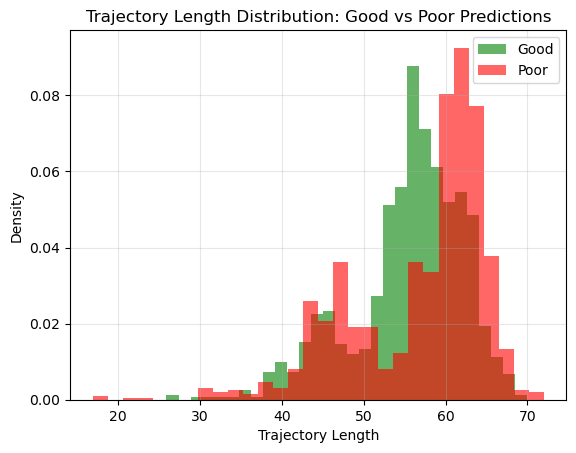

In [85]:
mean_good = np.mean(conds_good, axis=1)
mean_bad = np.mean(conds_poor, axis=1)
_ = plt.hist(mean_good[:,2], bins=30, alpha=0.6, label='Good', color='green', density=True)
_ = plt.hist(mean_bad[:,2], bins=30, alpha=0.6, label='Poor', color='red', density=True)
plt.xlabel('Trajectory Length')
plt.ylabel('Density')
plt.title('Trajectory Length Distribution: Good vs Poor Predictions')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

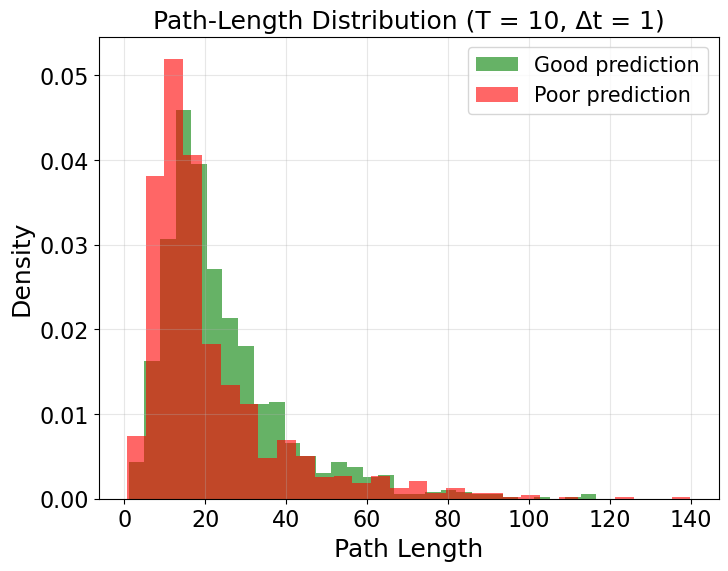

In [116]:
fig = plt.figure(figsize=(8,6))
_ = plt.hist(lengths_good, bins=30, alpha=0.6, label='Good prediction', color='green', density=True)
_ = plt.hist(lengths_poor, bins=30, alpha=0.6, label='Poor prediction', color='red', density=True)
# plt.xlabel('Trajectory Length')
plt.title('Path-Length Distribution (T = 10, Δt = 1)',fontsize=18)
plt.legend(fontsize=15)
plt.grid(True, alpha=0.3)
plt.tick_params(axis='both', which='major', labelsize=16)
plt.xlabel('Path Length', fontsize=18)
plt.ylabel('Density', fontsize=18)
plt.show()
fig.savefig('./results/plots/trajectory_length_distribution_good_vs_poor_T10.jpeg', dpi=300, bbox_inches='tight')

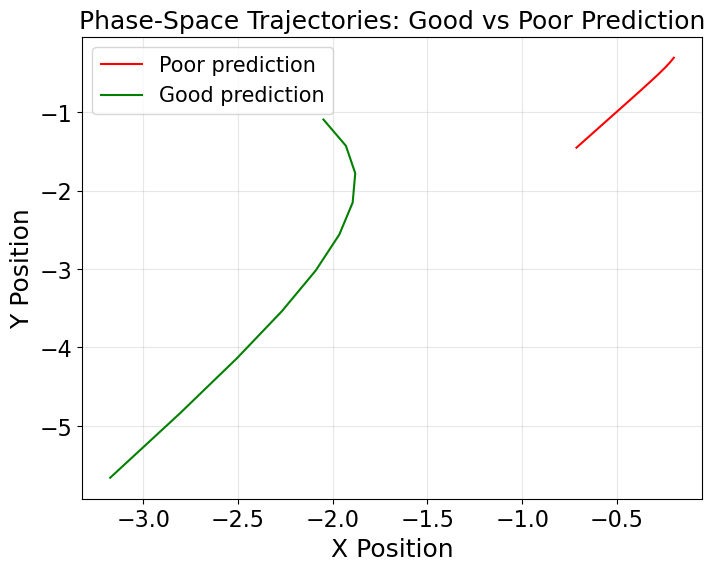

In [115]:
i = 121
ntmax = 50
fig= plt.figure(figsize=(8,6))
# plt.plot(conds[30*i,:ntmax,0], conds[30*i,:ntmax,2], alpha=0.3, color='green')
plt.plot(conds_poor[i,:ntmax,0], conds_poor[i,:ntmax,1], alpha=1, color='red')
plt.plot(conds_good[i,:ntmax,0], conds_good[i,:ntmax,1], alpha=1, color='green')
plt.legend(['Poor prediction', 'Good prediction'], fontsize=15)
plt.xlabel('X Position', fontsize=18)
plt.ylabel('Y Position', fontsize=18)
plt.title('Phase-Space Trajectories: Good vs Poor Prediction', fontsize=18)
plt.grid(True, alpha=0.3)
plt.tick_params(axis='both', which='major', labelsize=16)

plt.show()
fig.savefig(f'./results/plots/trajectory_comparison_good_vs_poor_{i}_T10.jpeg', dpi=300, bbox_inches='tight')

In [35]:
# models_dict[keys[14]]['conditionals'][:,:,1].shape


BEST PREDICTION ANALYSIS: study1_temporal_extent_T50_dt1_easy - rho
Total samples: 10240
Best predictions (≤10th percentile): 1024 (10.0%)
Other predictions: 9216 (90.0%)
Error threshold: 0.0028
✓ Saved analysis: ./results/plots/study1_temporal_extent_T50_dt1_easy_rho_best_prediction_analysis.png

STATISTICAL SUMMARY

Error Statistics:
  Best predictions:
    Mean error: 0.0014 ± 0.0008
    Median error: 0.0013
  Other predictions:
    Mean error: 0.0326 ± 0.0315
    Median error: 0.0216

True rho Statistics:
  Best predictions:
    Mean: 0.6261 ± 0.1838
    Range: [0.0000, 1.0000]
  Other predictions:
    Mean: 0.6090 ± 0.2061
    Range: [0.0000, 1.0000]
  KS test p-value: 0.000026
  → ⚠️  SIGNIFICANT difference in true value distribution!

Posterior Uncertainty Statistics:
  Best predictions:
    Mean std: 0.0275 ± 0.0129
  Other predictions:
    Mean std: 0.0388 ± 0.0150
  KS test p-value: 0.000000
  → ⚠️  SIGNIFICANT difference in posterior uncertainty!

Uncertainty-Error Correlat